# Exploratory Data Analysis — Supply Chain Demand Forecasting


---

**Project Context:** This notebook presents a comprehensive Exploratory Data Analysis (EDA) for a retail supply chain demand forecasting project. The goal is to understand demand patterns, evaluate external factors influencing sales, assess the quality of an existing baseline forecast, and identify the most promising directions for building improved predictive models.

**Key Questions This EDA Addresses:**
1. What are the underlying demand patterns and distributions?
2. Do temporal trends, seasonality, or day-of-week effects exist?
3. How do product categories and geographic regions compare in sales performance?
4. Do external factors (weather, holidays, discounts) meaningfully influence demand?
5. Which features are most correlated with sales, and which are redundant?
6. How accurate is the existing baseline forecast, and where does it fail?
7. Which products exhibit stable vs. volatile demand — and what does that imply for model selection?

TARGET VARIABLES FOR ML MODELS:
*   Nanditha - RF Regressor
*   Nandini - XGBoost
*   Narain - Light BGM
1. Sales by Month
Product vs quantity
Total sales vs Region
Product vs Holiday
Product vs Promotion

X:
Productid and name, category
unit and competitor price
inventory start and end values, stockoutflag
promotion and holiday flag

Y1 - probability of item being stockout
Y2 - sales quantity

---
## Section 1: Data Loading & Quality Check
**Purpose:** Load the dataset, inspect its structure, verify data integrity, and flag any quality issues before proceeding with analysis.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
file_path = "/content/drive/My Drive/Colab Notebooks/DSCapstone/supply_chain_demand_forecasting_v3.xlsx"

Mounted at /content/drive


In [ ]:
df = pd.read_excel(file_path)
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values(['Store Id', 'Product Id', 'Date']).reset_index(drop=True)

print(f'Shape: {df.shape}')
print(f'Date range: {df["Date"].min().date()} → {df["Date"].max().date()}')
df.head()

Shape: (26250, 20)
Date range: 2022-01-01 → 2023-12-30


,Date,Week Of Year,Year,Month,Store Id,Region,Product Id,Product Name,Category,Unit Price,Competitor Price,Sales Quantity,Inventory Start,Inventory End,Stockout Flag,Promotion Flag,Holiday Flag,Temperature F,Precipitation Mm,Baseline Forecast
0,2022-01-01,52,2022,1,Store_1,North,P001,Laptop,Electronics,430.60,427.49,31,117,86,0,0,1,17.9,100.5,13
1,2022-01-08,1,2022,1,Store_1,North,P001,Laptop,Electronics,373.99,429.47,42,86,44,0,1,1,11.8,59.5,16
2,2022-01-15,2,2022,1,Store_1,North,P001,Laptop,Electronics,443.93,437.34,19,44,25,0,0,0,9.6,76.3,15
3,2022-01-22,3,2022,1,Store_1,North,P001,Laptop,Electronics,459.20,419.56,15,25,10,0,0,0,27.5,77.9,26
4,2022-01-29,4,2022,1,Store_1,North,P001,Laptop,Electronics,464.06,423.27,19,74,55,0,0,0,11.7,88.9,19


In [ ]:
# Quick overview
print('=== Data Types ===')
print(df.dtypes)
print('\n=== Null Counts ===')
print(df.isnull().sum())
print('\n=== Basic Stats ===')
df.describe()

=== Data Types ===
Date                 datetime64[ns]
Week Of Year                  int64
Year                          int64
Month                         int64
Store Id                     object
Region                       object
Product Id                   object
Product Name                 object
Category                     object
Unit Price                  float64
Competitor Price            float64
Sales Quantity                int64
Inventory Start               int64
Inventory End                 int64
Stockout Flag                 int64
Promotion Flag                int64
Holiday Flag                  int64
Temperature F               float64
Precipitation Mm            float64
Baseline Forecast             int64
dtype: object

=== Null Counts ===
Date                 0
Week Of Year         0
Year                 0
Month                0
Store Id             0
Region               0
Product Id           0
Product Name         0
Category             0
Unit Price         

,Date,Week Of Year,Year,Month,Unit Price,Competitor Price,Sales Quantity,Inventory Start,Inventory End,Stockout Flag,Promotion Flag,Holiday Flag,Temperature F,Precipitation Mm,Baseline Forecast
count,26250,26250.000000,26250.000000,26250.000000,26250.000000,26250.000000,26250.000000,26250.000000,26250.000000,26250.000000,26250.000000,26250.000000,26250.000000,26250.000000,26250.000000
mean,2022-12-30 23:59:59.999999744,26.742857,2022.495238,6.571429,91.685231,97.604144,70.064076,133.598286,63.534210,0.136076,0.152152,0.228571,57.694933,56.057608,49.575657
min,2022-01-01 00:00:00,1.000000,2022.000000,1.000000,3.710000,4.060000,3.000000,10.000000,0.000000,0.000000,0.000000,0.000000,-5.000000,0.000000,5.000000
25%,2022-07-02 00:00:00,14.000000,2022.000000,4.000000,26.230000,27.805000,28.000000,50.000000,11.000000,0.000000,0.000000,0.000000,43.000000,34.300000,20.000000
50%,2022-12-31 00:00:00,27.000000,2022.000000,7.000000,41.740000,44.240000,46.000000,84.000000,33.000000,0.000000,0.000000,0.000000,62.200000,53.500000,34.000000
75%,2023-07-01 00:00:00,40.000000,2023.000000,10.000000,66.177500,69.860000,85.000000,150.000000,73.000000,0.000000,0.000000,0.000000,74.100000,74.700000,58.000000
max,2023-12-30 00:00:00,52.000000,2023.000000,12.000000,533.790000,607.520000,569.000000,1435.000000,1116.000000,1.000000,1.000000,1.000000,104.000000,183.800000,254.000000
std,NaN,15.140917,0.499987,3.472014,121.620497,129.765862,66.301017,136.793047,89.731472,0.342876,0.359175,0.419921,21.100326,29.282455,43.817099


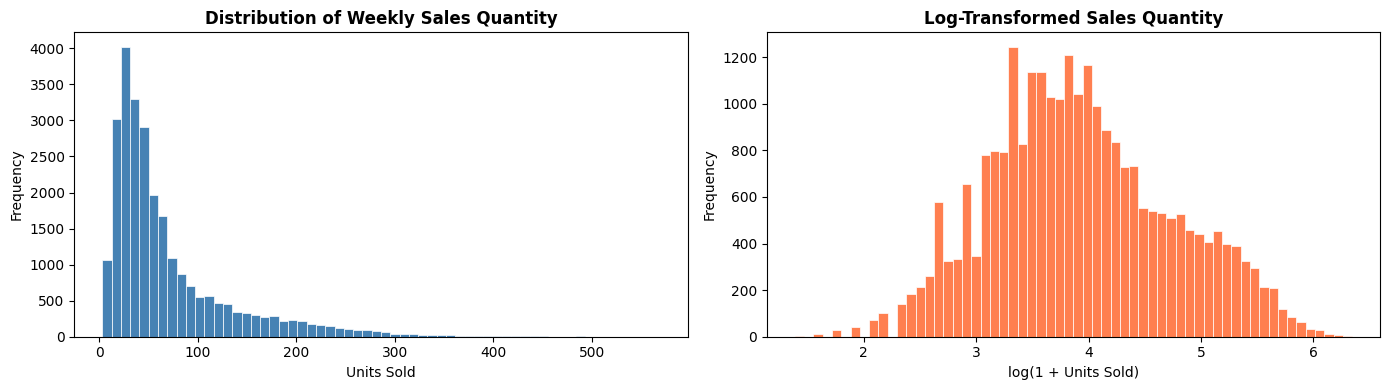

Skewness (raw):  2.120
Skewness (log1p): 0.232


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(df['Sales Quantity'], bins=60, color='steelblue', edgecolor='white', linewidth=0.5)
axes[0].set_title('Distribution of Weekly Sales Quantity', fontweight='bold')
axes[0].set_xlabel('Units Sold')
axes[0].set_ylabel('Frequency')

axes[1].hist(np.log1p(df['Sales Quantity']), bins=60, color='coral', edgecolor='white', linewidth=0.5)
axes[1].set_title('Log-Transformed Sales Quantity', fontweight='bold')
axes[1].set_xlabel('log(1 + Units Sold)')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

print(f'Skewness (raw):  {df["Sales Quantity"].skew():.3f}')
print(f'Skewness (log1p): {np.log1p(df["Sales Quantity"]).skew():.3f}')

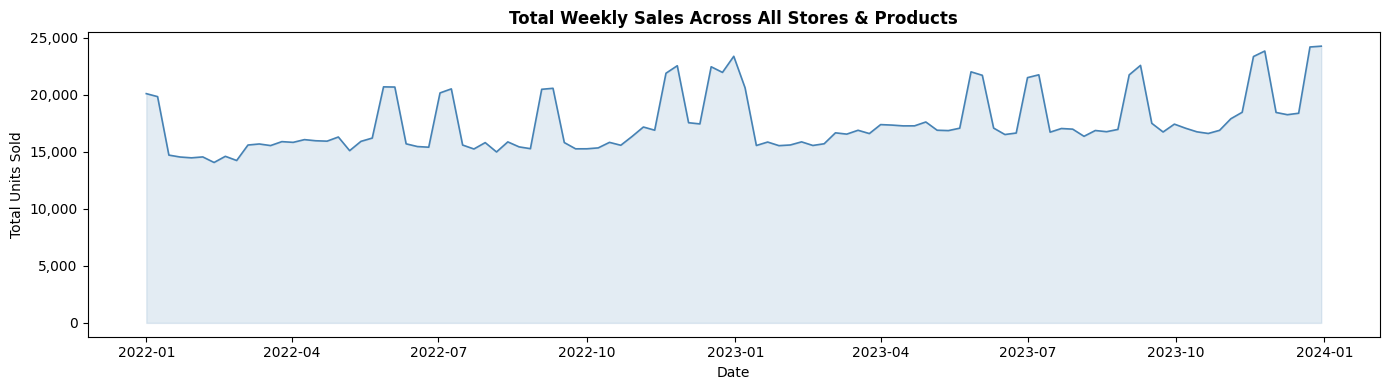

In [ ]:
# Overall weekly trend
import matplotlib.ticker as mticker
weekly = df.groupby('Date')['Sales Quantity'].sum().reset_index()

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(weekly['Date'], weekly['Sales Quantity'], color='steelblue', linewidth=1.2)
ax.fill_between(weekly['Date'], weekly['Sales Quantity'], alpha=0.15, color='steelblue')
ax.set_title('Total Weekly Sales Across All Stores & Products', fontweight='bold')
ax.set_xlabel('Date')
ax.set_ylabel('Total Units Sold')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
plt.tight_layout()
plt.show()

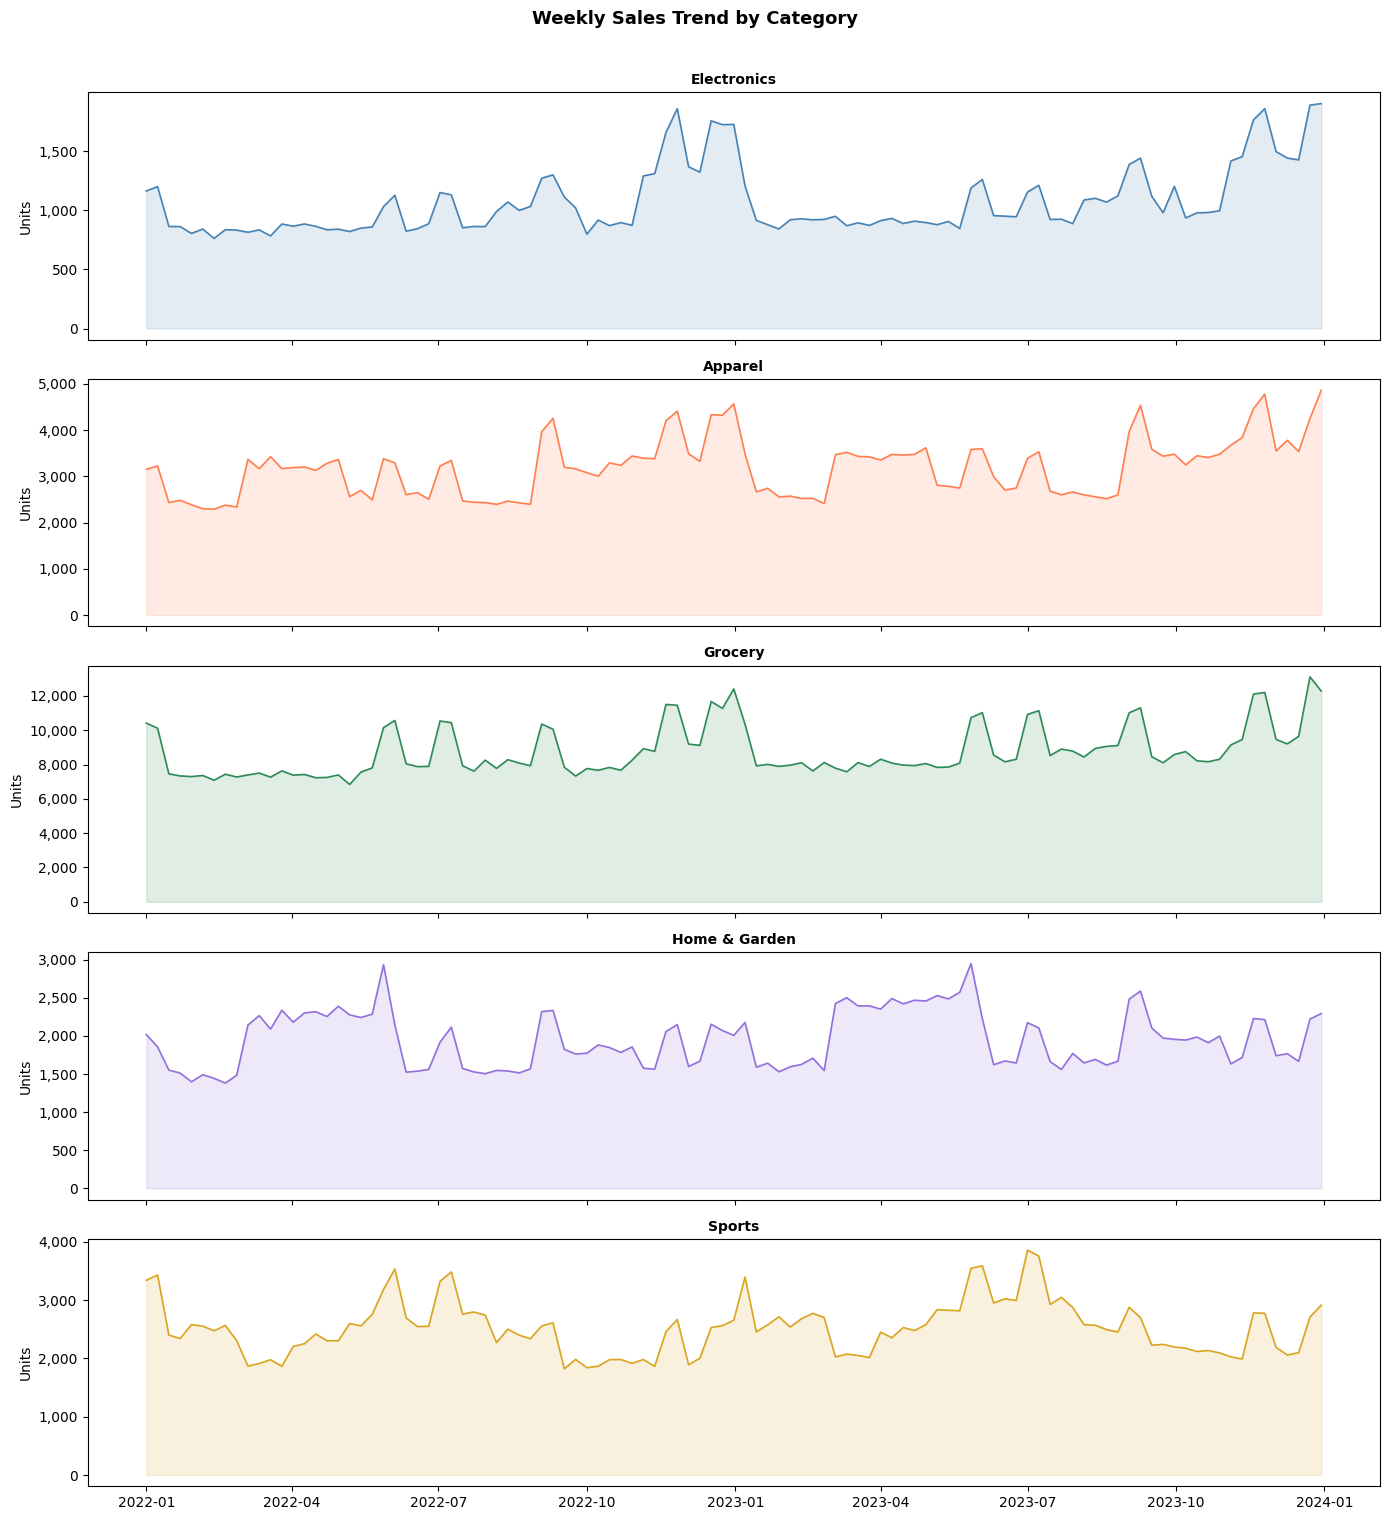

In [ ]:
# Weekly trend by category
cat_weekly = df.groupby(['Date', 'Category'])['Sales Quantity'].sum().reset_index()
categories = df['Category'].unique()

fig, axes = plt.subplots(len(categories), 1, figsize=(14, 3 * len(categories)), sharex=True)

colors = ['steelblue', 'coral', 'seagreen', 'mediumpurple', 'goldenrod']
for ax, cat, color in zip(axes, categories, colors):
    data = cat_weekly[cat_weekly['Category'] == cat]
    ax.plot(data['Date'], data['Sales Quantity'], color=color, linewidth=1.2)
    ax.fill_between(data['Date'], data['Sales Quantity'], alpha=0.15, color=color)
    ax.set_title(f'{cat}', fontweight='bold', fontsize=10)
    ax.set_ylabel('Units')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))

fig.suptitle('Weekly Sales Trend by Category', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

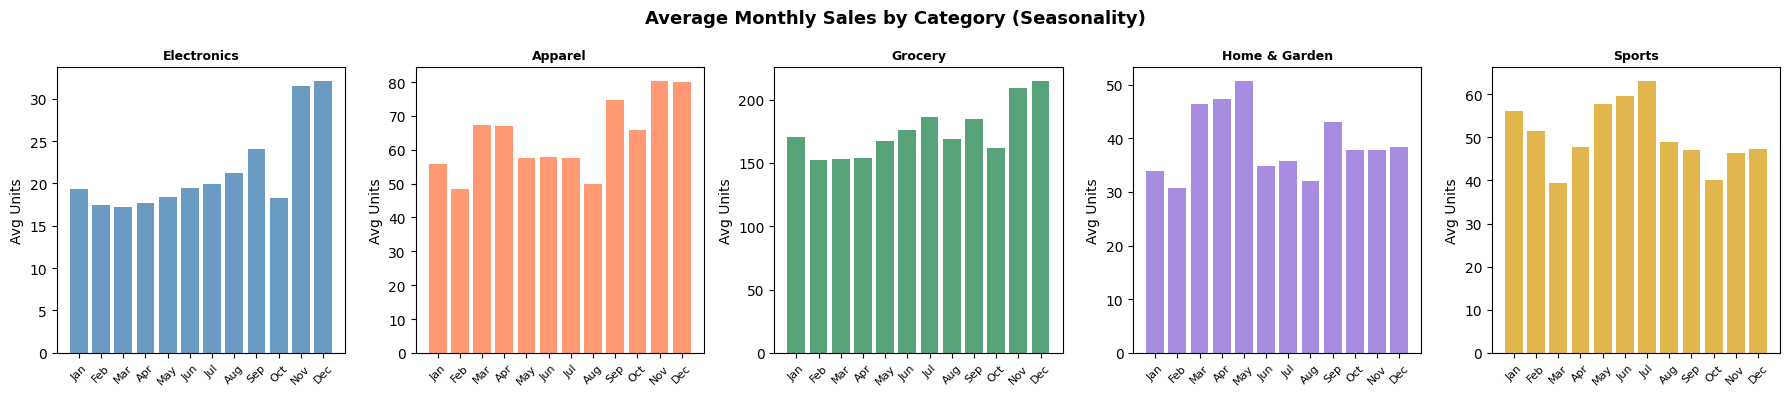

In [ ]:
# Average sales by month per category
month_names = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
monthly = df.groupby(['Month', 'Category'])['Sales Quantity'].mean().reset_index()

fig, axes = plt.subplots(1, len(categories), figsize=(18, 4), sharey=False)
for ax, cat, color in zip(axes, categories, colors):
    data = monthly[monthly['Category'] == cat].sort_values('Month')
    ax.bar(data['Month'], data['Sales Quantity'], color=color, alpha=0.8)
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(month_names, rotation=45, fontsize=8)
    ax.set_title(cat, fontweight='bold', fontsize=9)
    ax.set_ylabel('Avg Units')

fig.suptitle('Average Monthly Sales by Category (Seasonality)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

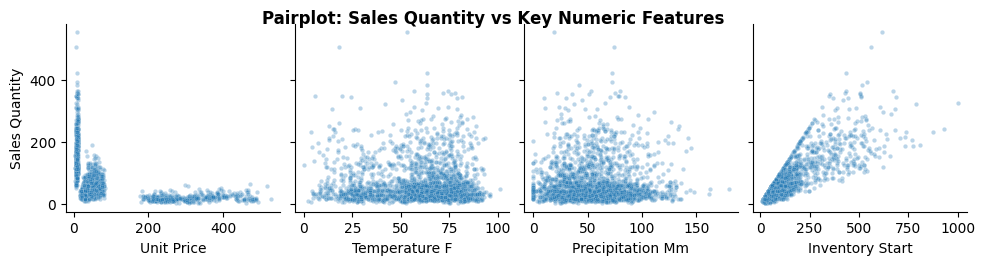

In [ ]:
# Pairplot: numeric features vs sales quantity
pairplot_cols = ['Sales Quantity', 'Unit Price', 'Temperature F',
                 'Precipitation Mm', 'Inventory Start']
sample = df[pairplot_cols].sample(2000, random_state=42)  # sample for speed

sns.pairplot(sample, y_vars=['Sales Quantity'],
             x_vars=['Unit Price','Temperature F','Precipitation Mm','Inventory Start'],
             plot_kws={'alpha': 0.3, 's': 10})
plt.suptitle('Pairplot: Sales Quantity vs Key Numeric Features', y=1.02, fontweight='bold')
plt.show()

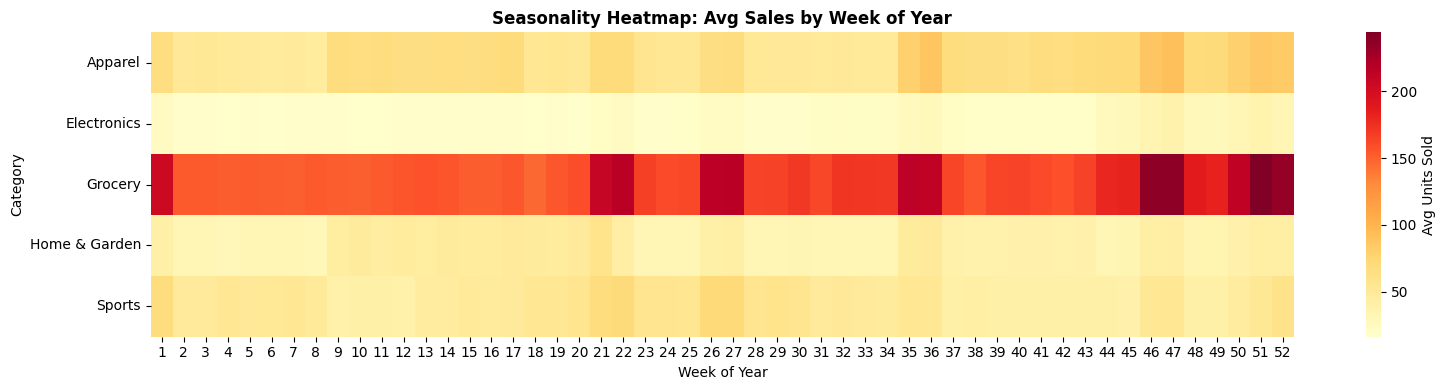

In [ ]:
# Heatmap: avg sales by week-of-year and category
heat_data = df.groupby(['Week Of Year', 'Category'])['Sales Quantity'].mean().unstack()

fig, ax = plt.subplots(figsize=(16, 4))
sns.heatmap(heat_data.T, cmap='YlOrRd', ax=ax, linewidths=0,
            cbar_kws={'label': 'Avg Units Sold'})
ax.set_title('Seasonality Heatmap: Avg Sales by Week of Year', fontweight='bold')
ax.set_xlabel('Week of Year')
ax.set_ylabel('Category')
plt.tight_layout()
plt.show()

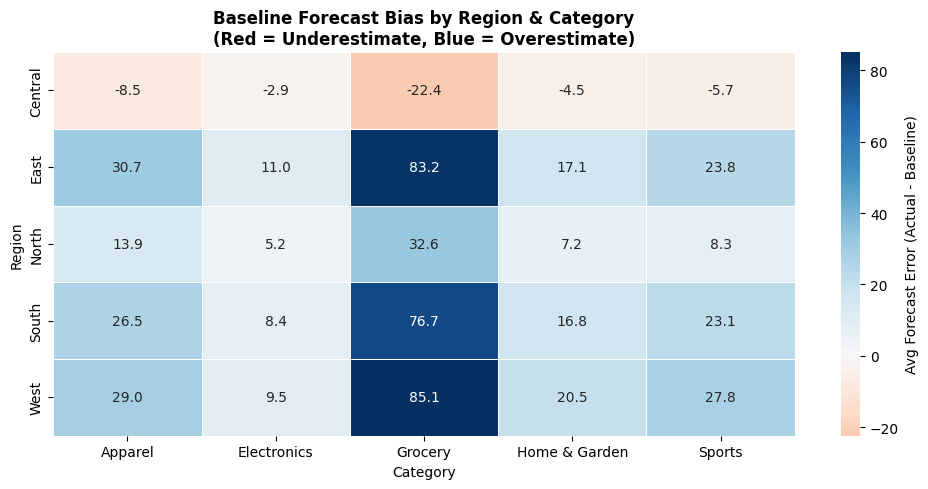

In [ ]:

#heatmap with -ve and +ve values visible
# Diverging heatmap — avg forecast error (Actual - Baseline) by Region & Category
# Positive = baseline underestimates, Negative = baseline overestimates
if 'forecast_error' not in df.columns:
    df['forecast_error'] = df['Sales Quantity'] - df['Baseline Forecast']

error_pivot = df.groupby(['Region', 'Category'])['forecast_error'].mean().unstack()

fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(error_pivot, cmap='RdBu', center=0, annot=True, fmt='.1f',
            linewidths=0.5, ax=ax,
            cbar_kws={'label': 'Avg Forecast Error (Actual - Baseline)'})
ax.set_title('Baseline Forecast Bias by Region & Category\n(Red = Underestimate, Blue = Overestimate)',
             fontweight='bold')
plt.tight_layout()
plt.show()

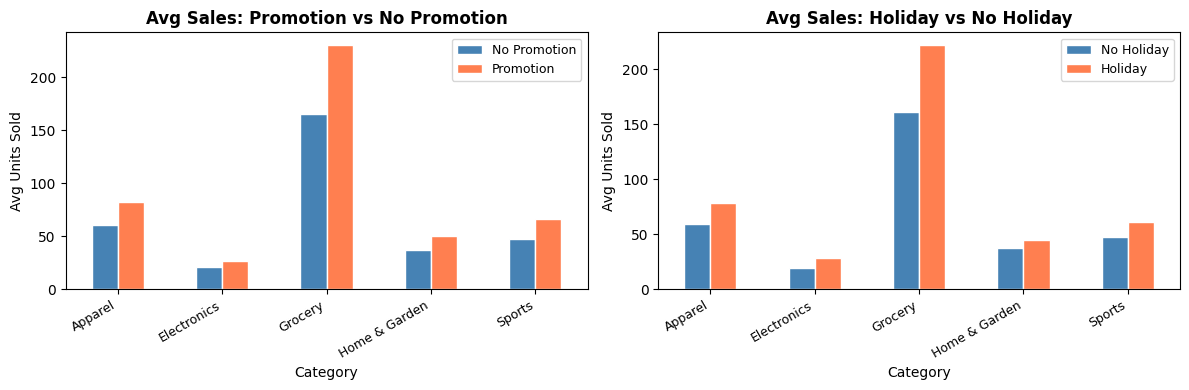

In [ ]:
# Promotion & holiday impact
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, col, label in zip(axes, ['Promotion Flag', 'Holiday Flag'], ['Promotion', 'Holiday']):
    grouped = df.groupby([col, 'Category'])['Sales Quantity'].mean().reset_index()
    pivot = grouped.pivot(index='Category', columns=col, values='Sales Quantity')
    pivot.columns = [f'No {label}', label]
    pivot.plot(kind='bar', ax=ax, color=['steelblue', 'coral'], edgecolor='white')
    ax.set_title(f'Avg Sales: {label} vs No {label}', fontweight='bold')
    ax.set_ylabel('Avg Units Sold')
    ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='right', fontsize=9)
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

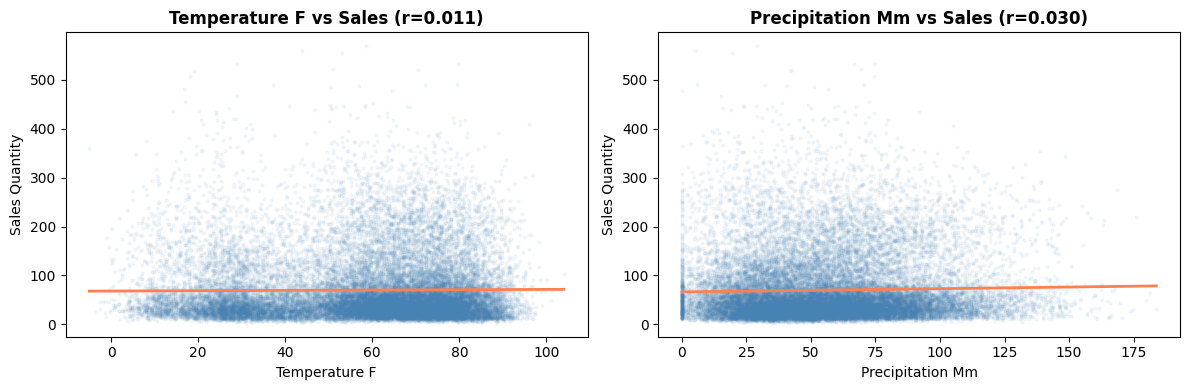

In [ ]:
# Correlation: temperature & precipitation vs sales
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, xcol in zip(axes, ['Temperature F', 'Precipitation Mm']):
    ax.scatter(df[xcol], df['Sales Quantity'], alpha=0.05, s=5, color='steelblue')
    # trend line
    z = np.polyfit(df[xcol], df['Sales Quantity'], 1)
    p = np.poly1d(z)
    xline = np.linspace(df[xcol].min(), df[xcol].max(), 100)
    ax.plot(xline, p(xline), color='coral', linewidth=2)
    corr = df[xcol].corr(df['Sales Quantity'])
    ax.set_title(f'{xcol} vs Sales (r={corr:.3f})', fontweight='bold')
    ax.set_xlabel(xcol)
    ax.set_ylabel('Sales Quantity')

plt.tight_layout()
plt.show()

Baseline MAE:  26.05
Baseline MAPE: 35.71%
← These are the numbers your models need to beat.


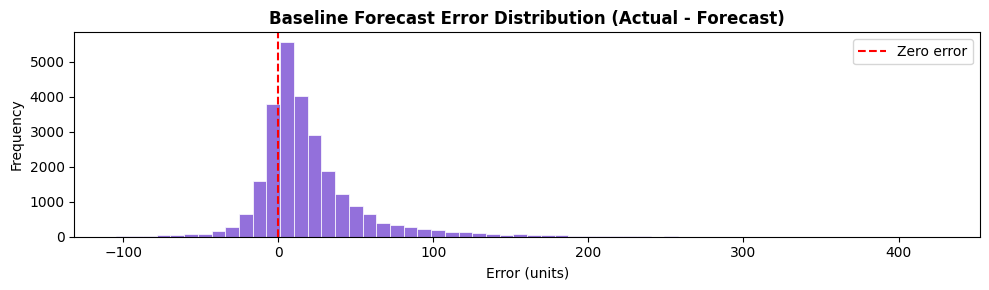

In [ ]:
# Baseline forecast error analysis
df['forecast_error'] = df['Sales Quantity'] - df['Baseline Forecast']
df['forecast_abs_error'] = df['forecast_error'].abs()

baseline_mae = df['forecast_abs_error'].mean()
baseline_mape = (df['forecast_abs_error'] / df['Sales Quantity'].replace(0, np.nan)).mean() * 100
print(f'Baseline MAE:  {baseline_mae:.2f}')
print(f'Baseline MAPE: {baseline_mape:.2f}%')
print('← These are the numbers your models need to beat.')

fig, ax = plt.subplots(figsize=(10, 3))
ax.hist(df['forecast_error'], bins=60, color='mediumpurple', edgecolor='white', linewidth=0.5)
ax.axvline(0, color='red', linestyle='--', linewidth=1.5, label='Zero error')
ax.set_title('Baseline Forecast Error Distribution (Actual - Forecast)', fontweight='bold')
ax.set_xlabel('Error (units)')
ax.set_ylabel('Frequency')
ax.legend()
plt.tight_layout()
plt.show()

/tmp/ipykernel_835/1718091855.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(store_sales.index, rotation=45, ha='right', fontsize=8)


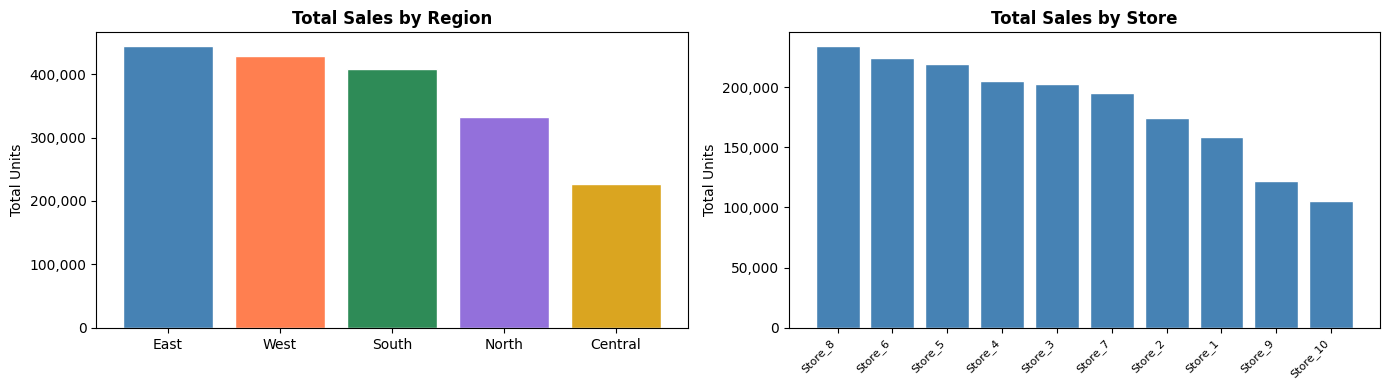

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# By region
region_sales = df.groupby('Region')['Sales Quantity'].sum().sort_values(ascending=False)
axes[0].bar(region_sales.index, region_sales.values, color=colors, edgecolor='white')
axes[0].set_title('Total Sales by Region', fontweight='bold')
axes[0].set_ylabel('Total Units')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))

# By store
store_sales = df.groupby('Store Id')['Sales Quantity'].sum().sort_values(ascending=False)
axes[1].bar(store_sales.index, store_sales.values, color='steelblue', edgecolor='white')
axes[1].set_title('Total Sales by Store', fontweight='bold')
axes[1].set_ylabel('Total Units')
axes[1].set_xticklabels(store_sales.index, rotation=45, ha='right', fontsize=8)
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))

plt.tight_layout()
plt.show()

# **FEATURE ENGINEERING**

In [ ]:
df_fe = df.copy()

# Quarter (1-4) — captures broad seasonal patterns
df_fe['quarter'] = df_fe['Date'].dt.quarter
# Day of year — more granular seasonal position
df_fe['day_of_year'] = df_fe['Date'].dt.dayofyear
# Binary flags for high-demand seasonal windows
df_fe['is_year_end'] = df_fe['Month'].isin([11, 12]).astype(int)  # Nov-Dec holiday shopping
df_fe['is_q1'] = (df_fe['quarter'] == 1).astype(int)              # Q1 post-holiday dip

# Cyclical encoding — month 12 and month 1 are adjacent in time but
# numerically distant as raw integers. Sin/cos places them on a circle.
df_fe['month_sin'] = np.sin(2 * np.pi * df_fe['Month'] / 12)
df_fe['month_cos'] = np.cos(2 * np.pi * df_fe['Month'] / 12)
df_fe['week_sin']  = np.sin(2 * np.pi * df_fe['Week Of Year'] / 52)
df_fe['week_cos']  = np.cos(2 * np.pi * df_fe['Week Of Year'] / 52)

print('Temporal features added:', ['quarter','day_of_year','is_year_end','is_q1','month_sin','month_cos','week_sin','week_cos'])

Temporal features added: ['quarter', 'day_of_year', 'is_year_end', 'is_q1', 'month_sin', 'month_cos', 'week_sin', 'week_cos']


In [ ]:
# Sort to ensure correct lag calculation per product+store
df_fe = df_fe.sort_values(['Store Id', 'Product Id', 'Date'])

group = df_fe.groupby(['Store Id', 'Product Id'])['Sales Quantity']

# Lags: 1 week, 2 weeks, 4 weeks (1 month), 52 weeks (1 year same week)
# NOTE on lag_52w: this will be NaN for the first 52 weeks of each series.
# During dropna() in preprocessing, lag_52w will be the largest source of row loss.
for lag in [1, 2, 4, 52]:
    df_fe[f'lag_{lag}w'] = group.shift(lag)

# Lag of baseline forecast (1 week ahead)
df_fe['lag_forecast_1w'] = df_fe.groupby(['Store Id', 'Product Id'])['Baseline Forecast'].shift(1)

# Report NaN counts per lag feature to anticipate row loss downstream
print('Lag features created:')
for lag in [1, 2, 4, 52]:
    n_null = df_fe[f'lag_{lag}w'].isnull().sum()
    pct    = n_null / len(df_fe) * 100
    print(f'  lag_{lag}w: {n_null:,} NaN rows ({pct:.1f}%) — warmup period')
print(f'  lag_52w drives the most row loss and will dominate the dropna() step.')

df_fe[['Date','Product Id','Store Id','Sales Quantity','lag_1w','lag_4w','lag_52w']].dropna().head(8)

Lag features created:
  lag_1w: 250 NaN rows (1.0%) — warmup period
  lag_2w: 500 NaN rows (1.9%) — warmup period
  lag_4w: 1,000 NaN rows (3.8%) — warmup period
  lag_52w: 13,000 NaN rows (49.5%) — warmup period
  lag_52w drives the most row loss and will dominate the dropna() step.


,Date,Product Id,Store Id,Sales Quantity,lag_1w,lag_4w,lag_52w
52,2022-12-31,P001,Store_1,57,39.0,31.0,31.0
53,2023-01-07,P001,Store_1,32,57.0,22.0,42.0
54,2023-01-14,P001,Store_1,34,32.0,34.0,19.0
55,2023-01-21,P001,Store_1,23,34.0,39.0,15.0
56,2023-01-28,P001,Store_1,28,23.0,57.0,19.0
57,2023-02-04,P001,Store_1,22,28.0,32.0,20.0
58,2023-02-11,P001,Store_1,32,22.0,34.0,15.0
59,2023-02-18,P001,Store_1,23,32.0,23.0,28.0


In [ ]:
group = df_fe.groupby(['Store Id', 'Product Id'])['Sales Quantity']

# Rolling mean & std over 4-week and 12-week windows
# IMPORTANT: .shift(1) before .rolling() prevents data leakage from the current week.
for window in [4, 12]:
    df_fe[f'rolling_mean_{window}w'] = group.transform(
        lambda x: x.shift(1).rolling(window, min_periods=1).mean()
    )
    df_fe[f'rolling_std_{window}w'] = group.transform(
        lambda x: x.shift(1).rolling(window, min_periods=1).std()
    )

# Rolling max (captures peak demand — useful for inventory)
df_fe['rolling_max_4w'] = group.transform(
    lambda x: x.shift(1).rolling(4, min_periods=1).max()
)

# Exponentially weighted mean (more weight on recent weeks)
df_fe['ewm_4w'] = group.transform(
    lambda x: x.shift(1).ewm(span=4, min_periods=1).mean()
)

# Coefficient of Variation (CV) = std / mean — demand volatility signal
# High CV products need different inventory strategies and are harder to forecast.
df_fe['cv_4w'] = (
    df_fe['rolling_std_4w'] / df_fe['rolling_mean_4w'].replace(0, np.nan)
).clip(upper=5)  # cap extreme CV from near-zero mean weeks

print('Rolling features added: rolling_mean_4w, rolling_mean_12w, rolling_std_4w,',
      'rolling_std_12w, rolling_max_4w, ewm_4w, cv_4w')
df_fe[['Date','Product Id','Sales Quantity','rolling_mean_4w','rolling_std_4w',
       'ewm_4w','cv_4w']].dropna().head(8)

Rolling features added: rolling_mean_4w, rolling_mean_12w, rolling_std_4w, rolling_std_12w, rolling_max_4w, ewm_4w, cv_4w


,Date,Product Id,Sales Quantity,rolling_mean_4w,rolling_std_4w,ewm_4w,cv_4w
2,2022-01-15,P001,19,36.500000,7.778175,37.875000,0.213101
3,2022-01-22,P001,15,30.666667,11.503623,28.244898,0.375118
4,2022-01-29,P001,19,26.750000,12.230427,22.158088,0.457212
5,2022-02-05,P001,20,23.750000,12.311918,20.788341,0.518397
6,2022-02-12,P001,15,18.250000,2.217356,20.457573,0.121499
7,2022-02-19,P001,28,17.250000,2.629956,18.211673,0.152461
8,2022-02-26,P001,23,20.500000,5.446712,22.193890,0.265693
9,2022-03-05,P001,25,21.500000,5.446712,22.519616,0.253335


In [ ]:
# Price deviation: how far is this week's price from the product's historical mean?
# Standardized (z-score) so different price ranges are comparable.
df_fe['price_vs_avg'] = df_fe.groupby('Product Id')['Unit Price'].transform(
    lambda x: (x - x.mean()) / x.std()
)

# Competitor price features (from RF notebook approach)
# Price_Ratio: are we cheaper or more expensive than competitors?
df_fe['price_ratio']  = df_fe['Unit Price'] / (df_fe['Competitor Price'] + 1e-6)
# Price_Diff: absolute price gap vs competitor
df_fe['price_diff']   = df_fe['Competitor Price'] - df_fe['Unit Price']

# Lagged promotion flag: was there a promotion LAST week?
# Captures post-promo hangover (customers stocked up → lower demand next week)
df_fe['lag_promo_1w'] = df_fe.groupby(['Store Id', 'Product Id'])['Promotion Flag'].shift(1)

# Interaction: weeks with BOTH a promotion AND a holiday active
df_fe['promo_x_holiday'] = df_fe['Promotion Flag'] * df_fe['Holiday Flag']

# Sparsity check: near-zero rate means this interaction adds noise, not signal
promo_holiday_rate = df_fe['promo_x_holiday'].mean()
print(f'Price/promo features added: price_vs_avg, price_ratio, price_diff, lag_promo_1w, promo_x_holiday')
print(f'promo_x_holiday rate: {promo_holiday_rate:.4f}  '
      f'({"sparse" if promo_holiday_rate < 0.01 else "sufficient co-occurrence"})')

Price/promo features added: price_vs_avg, price_ratio, price_diff, lag_promo_1w, promo_x_holiday
promo_x_holiday rate: 0.0350  (sufficient co-occurrence)


In [ ]:
# Inventory coverage ratio: weeks of supply at current demand rate
df_fe['inventory_coverage'] = df_fe['Inventory Start'] / (df_fe['Sales Quantity'].replace(0, np.nan))

# Justify clip threshold using data quantiles
q95 = df_fe['inventory_coverage'].quantile(0.95)
q99 = df_fe['inventory_coverage'].quantile(0.99)
print(f'inventory_coverage 95th pct: {q95:.1f} weeks | 99th pct: {q99:.1f} weeks')
df_fe['inventory_coverage'] = df_fe['inventory_coverage'].clip(upper=20)

# Inventory change (from RF notebook) — direction of stock movement
df_fe['inventory_change'] = df_fe['Inventory End'] - df_fe['Inventory Start']
# Inventory ratio — what fraction of opening stock remained at close?
df_fe['inventory_ratio']  = df_fe['Inventory End'] / (df_fe['Inventory Start'] + 1e-6)

# Lag stockout flag
df_fe['lag_stockout_1w'] = df_fe.groupby(['Store Id', 'Product Id'])['Stockout Flag'].shift(1)

unique_vals = df_fe['Stockout Flag'].unique()
print(f'Stockout Flag unique values: {unique_vals}  '
      f'({"all zeros — lag_stockout_1w is a dead feature" if len(unique_vals)==1 else "has variation"})')
print('Inventory features: inventory_coverage, inventory_change, inventory_ratio, lag_stockout_1w')
print('Assumption: Inventory Start is observed before the week ends — no leakage.')

inventory_coverage 95th pct: 4.2 weeks | 99th pct: 5.7 weeks
Stockout Flag unique values: [0 1]  (has variation)
Inventory features: inventory_coverage, inventory_change, inventory_ratio, lag_stockout_1w
Assumption: Inventory Start is observed before the week ends — no leakage.


In [ ]:
all_features = [
    # --- Temporal (10) ---
    'Year', 'Month', 'Week Of Year', 'quarter', 'is_year_end', 'is_q1',
    'month_sin', 'month_cos', 'week_sin', 'week_cos',
    # --- Lags (4) ---
    'lag_1w', 'lag_2w', 'lag_4w', 'lag_52w',
    # --- Rolling (7) ---
    'rolling_mean_4w', 'rolling_mean_12w', 'rolling_std_4w', 'rolling_std_12w',
    'rolling_max_4w', 'ewm_4w', 'cv_4w',
    # --- External (6) ---
    'Temperature F', 'Precipitation Mm', 'Holiday Flag', 'Promotion Flag',
    'lag_promo_1w', 'promo_x_holiday',
    # --- Price (4) — added price_ratio + price_diff from RF notebook ---
    'Unit Price', 'price_vs_avg', 'price_ratio', 'price_diff',
    # --- Inventory (4) — added inventory_change + ratio from RF notebook ---
    #'inventory_coverage', 'inventory_change', 'inventory_ratio',
    'lag_stockout_1w',
    # --- Categorical (4) ---
    'Category', 'Region', 'Store Id', 'Product Id'
]

target = 'Sales Quantity'

print(f'Total features: {len(all_features)}')
print(f'Target: {target}')
print('\nNew vs original XGBoost notebook: +price_ratio, +price_diff, +inventory_change, +inventory_ratio, +cv_4w')

Total features: 36
Target: Sales Quantity

New vs original XGBoost notebook: +price_ratio, +price_diff, +inventory_change, +inventory_ratio, +cv_4w


# **PREPROCESSING**

In [ ]:
df_model = df_fe[all_features + [target, 'Date', 'Baseline Forecast']].copy()

total_rows = len(df_model)
print(f'Before dropping NaN rows: {df_model.shape}')

null_counts = df_model.isnull().sum()
null_counts = null_counts[null_counts > 0].sort_values(ascending=False)
if len(null_counts):
    print('\nNaN counts by feature (before drop):')
    for feat, cnt in null_counts.items():
        print(f'  {feat}: {cnt:,} ({cnt/total_rows*100:.1f}%)')

df_model = df_model.dropna()
rows_dropped = total_rows - len(df_model)
print(f'\nAfter dropping NaN rows: {df_model.shape}')
print(f'Rows dropped (lag warmup): {rows_dropped:,} ({rows_dropped/total_rows*100:.1f}%)')
if rows_dropped / total_rows > 0.20:
    print('  ↳ WARNING: >20% rows dropped — lag_52w warmup is the main cause.')

# Dropped-row bias check
dropped_df   = df_fe[all_features + [target, 'Date']].copy()
dropped_mask = dropped_df.isnull().any(axis=1)
if dropped_mask.sum() > 0 and 'Category' in dropped_df.columns:
    print('\nDropped rows by Category (check for sampling bias):')
    print(dropped_df[dropped_mask]['Category'].value_counts(normalize=True).round(3))

Before dropping NaN rows: (26250, 39)

NaN counts by feature (before drop):
  lag_52w: 13,000 (49.5%)
  lag_4w: 1,000 (3.8%)
  lag_2w: 500 (1.9%)
  rolling_std_12w: 500 (1.9%)
  rolling_std_4w: 500 (1.9%)
  cv_4w: 500 (1.9%)
  lag_1w: 250 (1.0%)
  rolling_mean_4w: 250 (1.0%)
  rolling_mean_12w: 250 (1.0%)
  rolling_max_4w: 250 (1.0%)
  ewm_4w: 250 (1.0%)
  lag_promo_1w: 250 (1.0%)
  lag_stockout_1w: 250 (1.0%)

After dropping NaN rows: (13250, 39)
Rows dropped (lag warmup): 13,000 (49.5%)
  ↳ WARNING: >20% rows dropped — lag_52w warmup is the main cause.

Dropped rows by Category (check for sampling bias):
Category
Electronics      0.2
Apparel          0.2
Grocery          0.2
Home & Garden    0.2
Sports           0.2
Name: proportion, dtype: float64


In [ ]:
# Time-based split — NEVER shuffle time series data
# Train: 2022 Jan – 2023 Aug  (~80%)
# Val:   2023 Sep – 2023 Oct  (~10%)
# Test:  2023 Nov – 2023 Dec  (~10%)
train_end = '2023-08-31'
val_end   = '2023-10-31'

train = df_model[df_model['Date'] <= train_end]
val   = df_model[(df_model['Date'] > train_end) & (df_model['Date'] <= val_end)]
test  = df_model[df_model['Date'] > val_end]

print(f'Train: {train["Date"].min().date()} → {train["Date"].max().date()} | {len(train):,} rows')
print(f'Val:   {val["Date"].min().date()  } → {val["Date"].max().date()  } | {len(val):,} rows')
print(f'Test:  {test["Date"].min().date() } → {test["Date"].max().date() } | {len(test):,} rows')

X_train = train[all_features]
y_train = train[target]
X_val   = val[all_features]
y_val   = val[target]
X_test  = test[all_features]
y_test  = test[target]

# Store baselines for benchmark comparison (LightGBM notebook pattern)
baseline_train = train['Baseline Forecast']
baseline_val   = val['Baseline Forecast']
baseline_test  = test['Baseline Forecast']

# Distribution shift check — test (Nov-Dec) often has higher holiday demand
print('\n=== Target Distribution Across Splits ===')
for name, y in [('Train', y_train), ('Val', y_val), ('Test', y_test)]:
    print(f'  {name}: mean={y.mean():.1f}, std={y.std():.1f}, min={y.min()}, max={y.max()}')
print('\nNote: If Test mean >> Train mean, is_year_end feature should help model adapt.')

Train: 2022-12-31 → 2023-08-26 | 8,750 rows
Val:   2023-09-02 → 2023-10-28 | 2,250 rows
Test:  2023-11-04 → 2023-12-30 | 2,250 rows

=== Target Distribution Across Splits ===
  Train: mean=70.0, std=65.2, min=3, max=560
  Val: mean=72.6, std=68.0, min=5, max=523
  Test: mean=83.1, std=81.2, min=6, max=569

Note: If Test mean >> Train mean, is_year_end feature should help model adapt.


In [ ]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import TimeSeriesSplit

In [ ]:
# Binary flags (0/1) are scale-invariant for tree-based models — no scaling needed.
# Continuous numeric features are scaled for any linear/distance-based models.
binary_features = [
    'is_year_end', 'is_q1', 'Holiday Flag', 'Promotion Flag',
    'lag_promo_1w', 'promo_x_holiday', 'lag_stockout_1w'
]

continuous_features = [
    'Year', 'Month', 'Week Of Year', 'quarter',
    'month_sin', 'month_cos', 'week_sin', 'week_cos',
    'lag_1w', 'lag_2w', 'lag_4w', 'lag_52w',
    'rolling_mean_4w', 'rolling_mean_12w', 'rolling_std_4w', 'rolling_std_12w',
    'rolling_max_4w', 'ewm_4w', 'cv_4w',
    'Temperature F', 'Precipitation Mm',
    'Unit Price', 'price_vs_avg',
    #'inventory_coverage',
    'price_ratio', 'price_diff',
    #'inventory_change', 'inventory_ratio',
]

categorical_features = ['Category', 'Region', 'Store Id', 'Product Id']

# Verify no features are missing or double-counted
all_assigned = set(continuous_features + binary_features + categorical_features)
missing = set(all_features) - all_assigned
extra   = all_assigned - set(all_features)
if missing: print(f'WARNING — features not assigned to any transformer: {missing}')
if extra:   print(f'WARNING — features in transformer not in all_features: {extra}')

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(transformers=[
    ('scale', StandardScaler(), continuous_features),
    ('pass',  'passthrough',    binary_features),        # no scaling for 0/1 flags
    ('cat',   OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
])

# Fit on train, transform all splits
X_train_proc = preprocessor.fit_transform(X_train)
X_val_proc   = preprocessor.transform(X_val)
X_test_proc  = preprocessor.transform(X_test)

print(f'Processed feature matrix shape (train): {X_train_proc.shape}')
print('Preprocessor fit on TRAIN only — no data leakage.')
print(f'  Scaled: {len(continuous_features)} continuous features')
print(f'  Passed through: {len(binary_features)} binary flags')
print(f'  One-hot encoded: {len(categorical_features)} categoricals')

Processed feature matrix shape (train): (8750, 77)
Preprocessor fit on TRAIN only — no data leakage.
  Scaled: 25 continuous features
  Passed through: 7 binary flags
  One-hot encoded: 4 categoricals


In [ ]:
# TimeSeriesSplit — for tuning models without leaking future data
tscv = TimeSeriesSplit(n_splits=5)

print('TimeSeriesSplit with 5 folds:')
for fold, (train_idx, val_idx) in enumerate(tscv.split(X_train_proc), 1):
    print(f'  Fold {fold}: train={len(train_idx):,} rows | val={len(val_idx):,} rows')

TimeSeriesSplit with 5 folds:
  Fold 1: train=1,460 rows | val=1,458 rows
  Fold 2: train=2,918 rows | val=1,458 rows
  Fold 3: train=4,376 rows | val=1,458 rows
  Fold 4: train=5,834 rows | val=1,458 rows
  Fold 5: train=7,292 rows | val=1,458 rows


In [ ]:
# Save splits to use in modeling notebooks
train.to_csv('train_set.csv', index=False)
val.to_csv('val_set.csv', index=False)
test.to_csv('test_set.csv', index=False)

# Save full feature-engineered dataset
df_model.to_csv('df_model_ready.csv', index=False)

print('Saved: train_set.csv, val_set.csv, test_set.csv, df_model_ready.csv')
print(f'\nFeatures ready for modeling: {len(all_features)}')
print(f'Target: {target}')
print('\nBaseline to beat:')
print(f'  MAE  = {baseline_mae:.2f} units')
print(f'  MAPE = {baseline_mape:.2f}%')

Saved: train_set.csv, val_set.csv, test_set.csv, df_model_ready.csv

Features ready for modeling: 36
Target: Sales Quantity

Baseline to beat:
  MAE  = 26.05 units
  MAPE = 35.71%


Add x and y variable details here

In [ ]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# ── Encode categoricals for XGBoost ──────────────────────────────────────
# LabelEncoder imposes an ordinal relationship (Store1 < Store2 < Store3)
# which doesn't exist for nominal categories. We use target encoding instead:
# each category level is replaced by the mean of the target in the TRAINING set.
# This avoids spurious ordinal relationships while capturing category-level
# demand signal in a single numeric column.

X_train = train[all_features].copy()
y_train = train['Sales Quantity']
X_val   = val[all_features].copy()
y_val   = val['Sales Quantity']
X_test  = test[all_features].copy()
y_test  = test['Sales Quantity']

cat_cols = ['Category', 'Region', 'Store Id', 'Product Id']
target_enc = {}  # store encodings for reproducibility

for col in cat_cols:
    # Compute mean target per level on TRAIN only (no leakage)
    means = y_train.groupby(X_train[col]).mean()
    global_mean = y_train.mean()  # fallback for unseen levels
    target_enc[col] = means
    X_train[col] = X_train[col].map(means).fillna(global_mean)
    X_val[col]   = X_val[col].map(means).fillna(global_mean)
    X_test[col]  = X_test[col].map(means).fillna(global_mean)

print('Target encoding done — each category level replaced by its mean sales (train only).')
print('X_train shape:', X_train.shape)
print('\nSample encoding for Category:')
print(target_enc['Category'].round(2))

Target encoding done — each category level replaced by its mean sales (train only).
X_train shape: (8750, 36)

Sample encoding for Category:
Category
Apparel           60.80
Electronics       19.87
Grocery          174.03
Home & Garden     40.54
Sports            54.94
Name: Sales Quantity, dtype: float64


In [ ]:
# ── Reusable evaluation function — consistent metric reporting across models ──
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluate_model(y_true, y_pred, label='Model'):
    """
    Compute MAE, RMSE, MAPE, R² and print a formatted summary.
    Matches the evaluate_model() pattern used in the LightGBM notebook.
    """
    if hasattr(y_true, 'values'): y_true = y_true.values
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mask = y_true > 0
    mape = (np.abs(y_true[mask] - y_pred[mask]) / y_true[mask]).mean() * 100
    r2   = r2_score(y_true, y_pred)
    print(f'{label}:')
    print(f'  MAE  = {mae:.2f} units')
    print(f'  RMSE = {rmse:.2f} units')
    print(f'  MAPE = {mape:.2f}%')
    print(f'  R²   = {r2:.4f}')
    return {'label': label, 'MAE': mae, 'RMSE': rmse, 'MAPE': mape, 'R2': r2}

# Results tracker — collects metrics from each model for final comparison table
results = []

In [ ]:
from xgboost import XGBRegressor
import numpy as np

xgb_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    early_stopping_rounds=20,
    eval_metric='rmse'
)

xgb_model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    verbose=50
)

# Clip negatives — XGBoost can predict < 0; sales cannot be negative
y_pred_val_raw  = xgb_model.predict(X_val)
y_pred_test_raw = xgb_model.predict(X_test)
neg_val  = (y_pred_val_raw < 0).sum()
neg_test = (y_pred_test_raw < 0).sum()
if neg_val + neg_test > 0:
    print(f'Negative predictions clipped: val={neg_val}, test={neg_test}')
y_pred_val  = np.clip(y_pred_val_raw,  0, None)
y_pred_test = np.clip(y_pred_test_raw, 0, None)

print('\n=== XGBoost (Default) — Model Performance ===')
r_val  = evaluate_model(y_val,  y_pred_val,  'Validation')
print()
r_test = evaluate_model(y_test, y_pred_test, 'Test')
results.append({**r_test, 'model': 'XGBoost (Default)'})

print('\n=== Baseline Comparison ===')
bl_val  = evaluate_model(y_val,  baseline_val.values,  'Baseline (Val)')
print()
bl_test = evaluate_model(y_test, baseline_test.values, 'Baseline (Test)')
results.append({**bl_test, 'model': 'Baseline Forecast'})

improvement_mae = (bl_test['MAE'] - r_test['MAE']) / bl_test['MAE'] * 100
print(f'\nMAE improvement over baseline: {improvement_mae:.1f}%')

[0]	validation_0-rmse:64.96629
[50]	validation_0-rmse:17.21113
[100]	validation_0-rmse:16.12133
[150]	validation_0-rmse:15.98303
[200]	validation_0-rmse:15.91810
[250]	validation_0-rmse:15.85850
[280]	validation_0-rmse:15.87687

=== XGBoost (Default) — Model Performance ===
Validation:
  MAE  = 9.80 units
  RMSE = 15.85 units
  MAPE = 17.18%
  R²   = 0.9456

Test:
  MAE  = 12.54 units
  RMSE = 21.64 units
  MAPE = 16.86%
  R²   = 0.9289

=== Baseline Comparison ===
Baseline (Val):
  MAE  = 28.65 units
  RMSE = 46.51 units
  MAPE = 36.65%
  R²   = 0.5319

Baseline (Test):
  MAE  = 34.46 units
  RMSE = 56.42 units
  MAPE = 38.33%
  R²   = 0.5167

MAE improvement over baseline: 63.6%


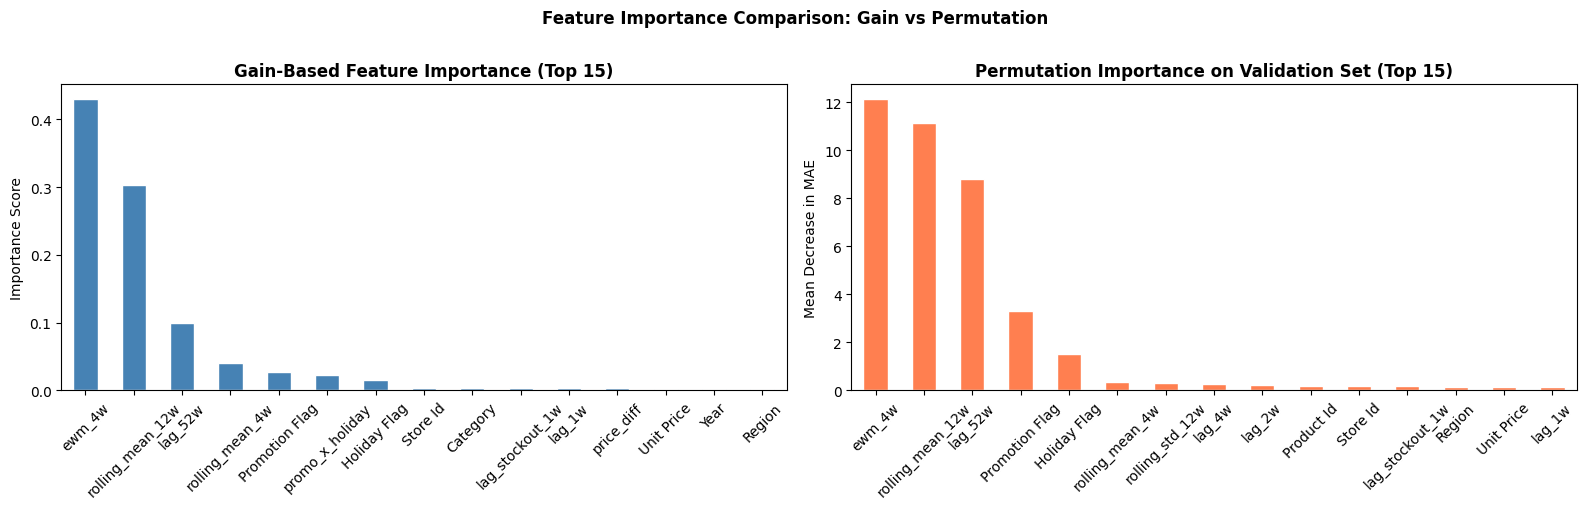

If rankings differ significantly between gain and permutation,
prefer permutation importance — it is less biased toward high-cardinality features.

Top 10 by permutation:
ewm_4w              12.1352
rolling_mean_12w    11.1157
lag_52w              8.8204
Promotion Flag       3.3101
Holiday Flag         1.5243
rolling_mean_4w      0.3629
rolling_std_12w      0.3246
lag_4w               0.2728
lag_2w               0.2238
Product Id           0.1882
dtype: float64


In [ ]:
from sklearn.inspection import permutation_importance

# ── 1. Default gain-based importance (fast, but biased toward high-cardinality features) ──
importance_gain = pd.Series(
    xgb_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

# ── 2. Permutation importance on validation set (more reliable, model-agnostic) ──
perm = permutation_importance(
    xgb_model, X_val, y_val,
    n_repeats=10, random_state=42,
    scoring='neg_mean_absolute_error'
)
importance_perm = pd.Series(
    perm.importances_mean, index=X_val.columns
).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

importance_gain.head(15).plot(kind='bar', ax=axes[0], color='steelblue', edgecolor='white')
axes[0].set_title('Gain-Based Feature Importance (Top 15)', fontweight='bold')
axes[0].set_ylabel('Importance Score')
axes[0].tick_params(axis='x', rotation=45)

importance_perm.head(15).plot(kind='bar', ax=axes[1], color='coral', edgecolor='white')
axes[1].set_title('Permutation Importance on Validation Set (Top 15)', fontweight='bold')
axes[1].set_ylabel('Mean Decrease in MAE')
axes[1].tick_params(axis='x', rotation=45)

plt.suptitle('Feature Importance Comparison: Gain vs Permutation', fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

print('If rankings differ significantly between gain and permutation,')
print('prefer permutation importance — it is less biased toward high-cardinality features.')
print('\nTop 10 by permutation:')
print(importance_perm.head(10).round(4))

=== Log-Target XGBoost (Test Set) ===
XGBoost (Log-Target) — Test:
  MAE  = 12.55 units
  RMSE = 21.34 units
  MAPE = 16.69%
  R²   = 0.9309

=== Raw-Target XGBoost (Test Set) — for comparison ===
XGBoost (Raw-Target) — Test:
  MAE  = 12.54 units
  RMSE = 21.64 units
  MAPE = 16.86%
  R²   = 0.9289


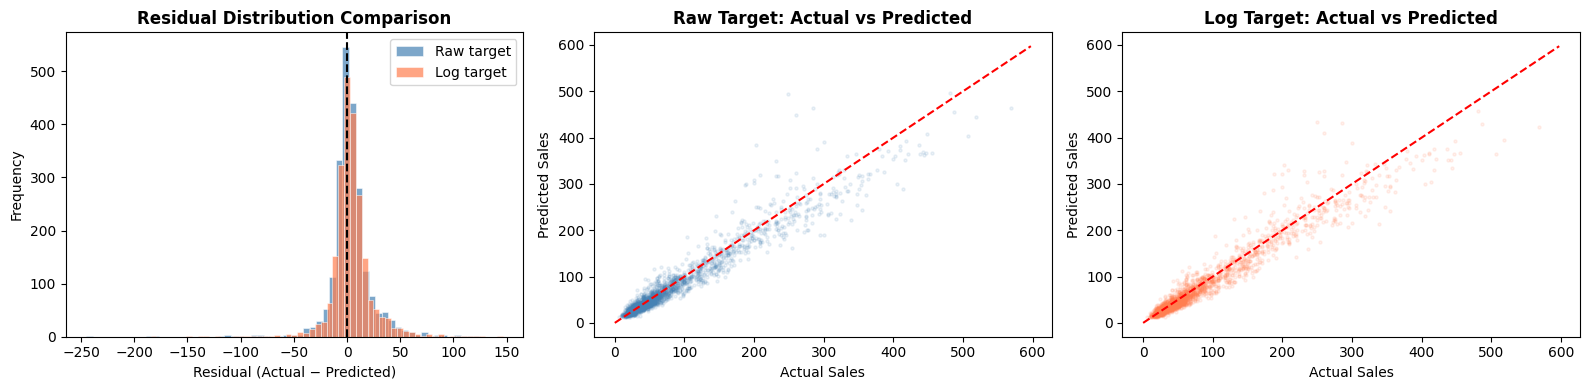


=== Summary: Raw vs Log Target ===
Metric            Raw        Log     Better
------------------------------------------
MAE             12.54      12.55        Raw
RMSE            21.64      21.34        Log

Note: Log transform helps most when the model consistently under-predicts
high-demand spikes. Check scatter plots — if Log closes the gap at high values,
use log-target for the final tuned model.


In [ ]:
# ── Log-Transform Target Experiment ──────────────────────────────────────
# Why: Sales Quantity is right-skewed (~2.0). log1p compresses large spikes,
# making the loss landscape more symmetric and improving RMSE on average.
# Method: train on log1p(y), predict, then inverse-transform with expm1().

import numpy as np

# Log-transform targets
y_train_log = np.log1p(y_train)
y_val_log   = np.log1p(y_val)

xgb_log = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    early_stopping_rounds=20,
    eval_metric='rmse'
)

xgb_log.fit(
    X_train, y_train_log,
    eval_set=[(X_val, y_val_log)],
    verbose=False
)

# Inverse-transform predictions back to original scale
y_pred_val_log  = np.clip(np.expm1(xgb_log.predict(X_val)),  0, None)
y_pred_test_log = np.clip(np.expm1(xgb_log.predict(X_test)), 0, None)

print('=== Log-Target XGBoost (Test Set) ===')
r_log = evaluate_model(y_test, y_pred_test_log, 'XGBoost (Log-Target) — Test')
results.append({**r_log, 'model': 'XGBoost (Log-Target)'})

print('\n=== Raw-Target XGBoost (Test Set) — for comparison ===')
evaluate_model(y_test, y_pred_test, 'XGBoost (Raw-Target) — Test')

# Visual comparison: residual distributions side by side
res_raw = y_test.values - y_pred_test
res_log = y_test.values - y_pred_test_log

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Residual distributions
axes[0].hist(res_raw, bins=60, color='steelblue', alpha=0.7,
             edgecolor='white', linewidth=0.5, label='Raw target')
axes[0].hist(res_log, bins=60, color='coral',     alpha=0.7,
             edgecolor='white', linewidth=0.5, label='Log target')
axes[0].axvline(0, color='black', linestyle='--', linewidth=1.5)
axes[0].set_title('Residual Distribution Comparison', fontweight='bold')
axes[0].set_xlabel('Residual (Actual − Predicted)')
axes[0].set_ylabel('Frequency')
axes[0].legend()

# Actual vs predicted — raw
axes[1].scatter(y_test.values, y_pred_test, alpha=0.1, s=5, color='steelblue')
lim = max(y_test.max(), y_pred_test.max()) * 1.05
axes[1].plot([0, lim], [0, lim], 'r--', linewidth=1.5)
axes[1].set_title('Raw Target: Actual vs Predicted', fontweight='bold')
axes[1].set_xlabel('Actual Sales'); axes[1].set_ylabel('Predicted Sales')

# Actual vs predicted — log
axes[2].scatter(y_test.values, y_pred_test_log, alpha=0.1, s=5, color='coral')
axes[2].plot([0, lim], [0, lim], 'r--', linewidth=1.5)
axes[2].set_title('Log Target: Actual vs Predicted', fontweight='bold')
axes[2].set_xlabel('Actual Sales'); axes[2].set_ylabel('Predicted Sales')

plt.tight_layout()
plt.show()

# Summary
from sklearn.metrics import mean_absolute_error, mean_squared_error
mae_raw = mean_absolute_error(y_test, y_pred_test)
mae_log = mean_absolute_error(y_test, y_pred_test_log)
rmse_raw = np.sqrt(mean_squared_error(y_test, y_pred_test))
rmse_log = np.sqrt(mean_squared_error(y_test, y_pred_test_log))

print(f'\n=== Summary: Raw vs Log Target ===')
print(f'{'Metric':<10} {'Raw':>10} {'Log':>10} {'Better':>10}')
print('-' * 42)
print(f'{'MAE':<10} {mae_raw:>10.2f} {mae_log:>10.2f} {"Log" if mae_log < mae_raw else "Raw":>10}')
print(f'{'RMSE':<10} {rmse_raw:>10.2f} {rmse_log:>10.2f} {"Log" if rmse_log < rmse_raw else "Raw":>10}')
print('\nNote: Log transform helps most when the model consistently under-predicts')
print('high-demand spikes. Check scatter plots — if Log closes the gap at high values,')
print('use log-target for the final tuned model.')

SHAP version: 0.51.0
SHAP values computed on validation set: (2250, 36)
Each value = how much that feature pushes the prediction above/below the mean

--- SHAP Summary Plot ---


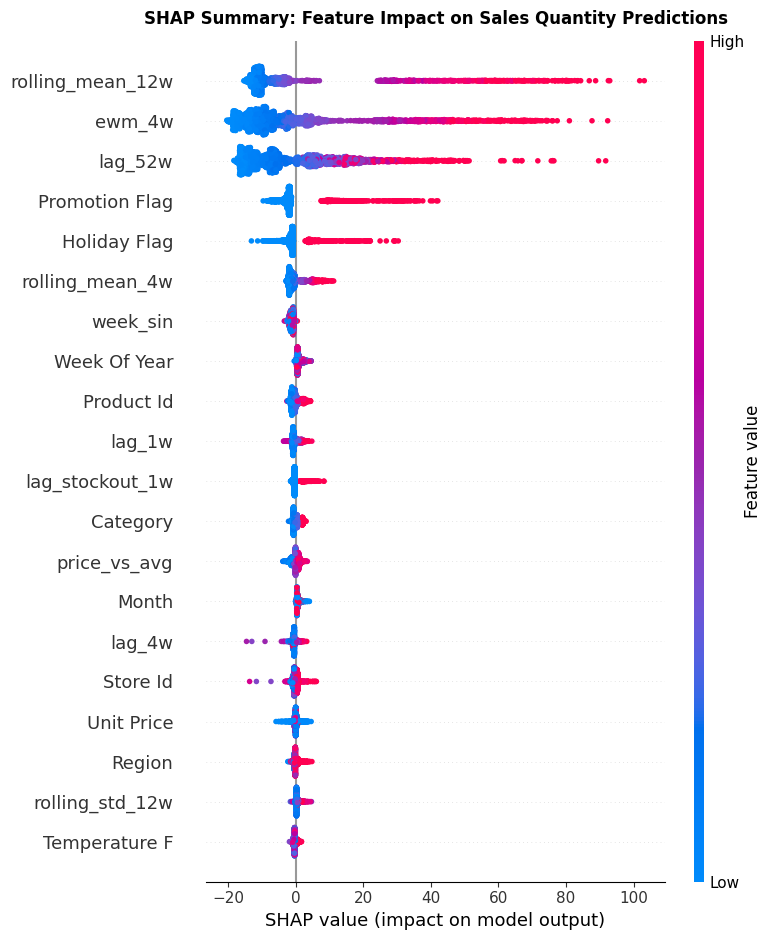

Reading guide:
  - Features ranked top→bottom by mean |SHAP value| (overall importance)
  - Each dot = one prediction. X position = SHAP value (impact on that prediction)
  - Colour = feature value: red = high, blue = low
  - Red dots right of 0 → high feature value pushes prediction UP
  - Blue dots right of 0 → low feature value pushes prediction UP

--- SHAP Dependence Plots (Top 4 Features) ---


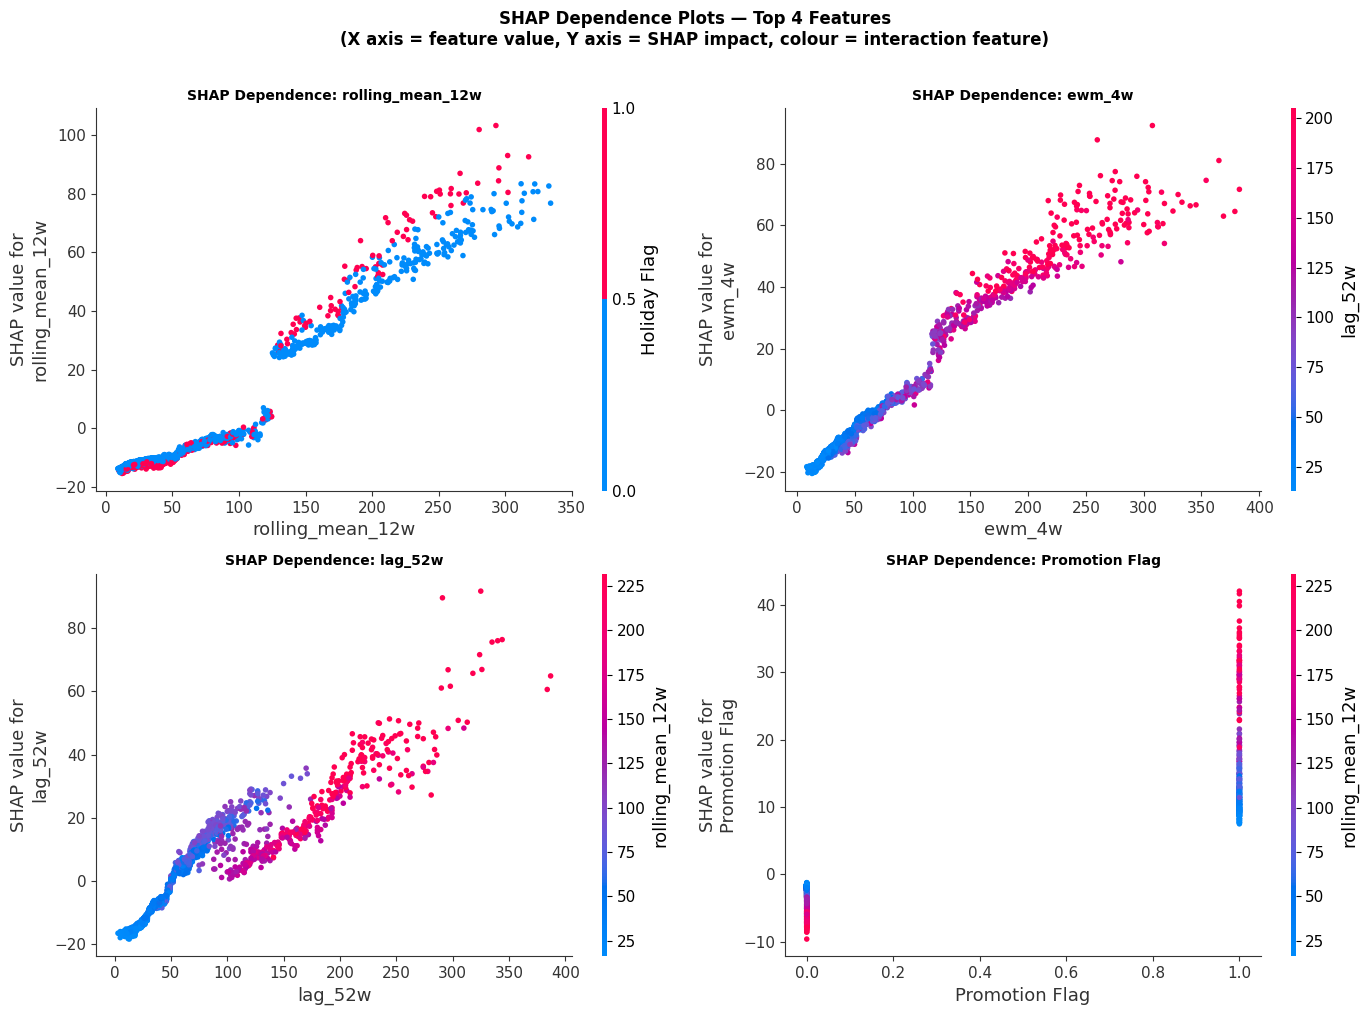


--- SHAP Waterfall: Single Prediction Breakdown ---


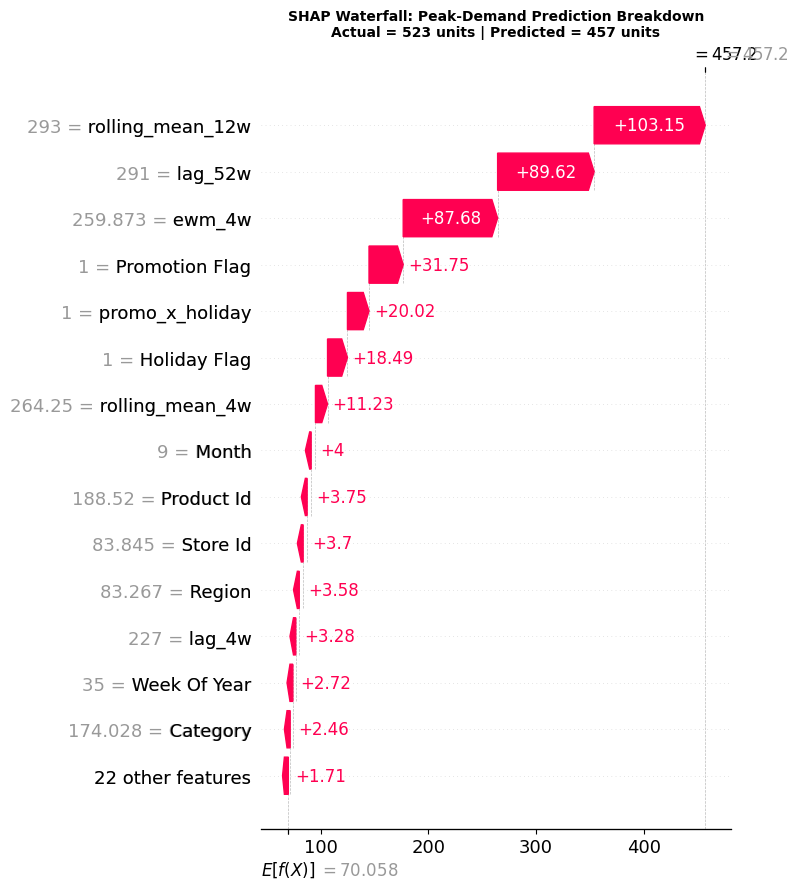


Top 15 features: SHAP rank vs Gain rank (large diff = gain is misleading)
         Feature  SHAP_Rank  Gain_Rank  Rank_Diff
rolling_mean_12w          1          2          1
          ewm_4w          2          1          1
         lag_52w          3          3          0
  Promotion Flag          4          5          1
    Holiday Flag          5          7          2
 rolling_mean_4w          6          4          2
        week_sin          7         22         15
    Week Of Year          8         17          9
      Product Id          9         21         12
          lag_1w         10         11          1
 lag_stockout_1w         11         10          1
        Category         12          9          3
    price_vs_avg         13         26         13
           Month         14         16          2
          lag_4w         15         19          4

Features where Gain_Rank >> SHAP_Rank are overvalued by gain importance.
Trust SHAP ranks for reporting to stakeholders.


In [ ]:
# ── SHAP Analysis ────────────────────────────────────────────────────────
try:
    import shap
    print(f'SHAP version: {shap.__version__}')
except ImportError:
    print('Installing SHAP...')
    import subprocess, sys
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'shap', '-q'])
    import shap
    print(f'SHAP version: {shap.__version__}')

# TreeExplainer is the fast, exact method for XGBoost
explainer   = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_val)

print(f'SHAP values computed on validation set: {shap_values.shape}')
print('Each value = how much that feature pushes the prediction above/below the mean')

# ── 1. Summary Plot — ranked by mean |SHAP|, colour = feature value ──────
print('\n--- SHAP Summary Plot ---')
plt.figure(figsize=(10, 9))
shap.summary_plot(
    shap_values, X_val,
    max_display=20,
    show=False
)
plt.title('SHAP Summary: Feature Impact on Sales Quantity Predictions',
          fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

print('Reading guide:')
print('  - Features ranked top→bottom by mean |SHAP value| (overall importance)')
print('  - Each dot = one prediction. X position = SHAP value (impact on that prediction)')
print('  - Colour = feature value: red = high, blue = low')
print('  - Red dots right of 0 → high feature value pushes prediction UP')
print('  - Blue dots right of 0 → low feature value pushes prediction UP')

# ── 2. Dependence Plots — top 4 features ─────────────────────────────────
print('\n--- SHAP Dependence Plots (Top 4 Features) ---')
mean_abs_shap = pd.Series(
    np.abs(shap_values).mean(axis=0),
    index=X_val.columns
).sort_values(ascending=False)

top4 = mean_abs_shap.head(4).index.tolist()
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, feat in zip(axes.flat, top4):
    shap.dependence_plot(
        feat, shap_values, X_val,
        ax=ax, show=False
    )
    ax.set_title(f'SHAP Dependence: {feat}', fontweight='bold', fontsize=10)

plt.suptitle('SHAP Dependence Plots — Top 4 Features\n'
             '(X axis = feature value, Y axis = SHAP impact, colour = interaction feature)',
             fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

# ── 3. Waterfall — single prediction breakdown ────────────────────────────
print('\n--- SHAP Waterfall: Single Prediction Breakdown ---')
# Pick the test row with the highest actual sales (most interesting case)
peak_idx = y_val.values.argmax()

shap_explanation = shap.Explanation(
    values        = shap_values[peak_idx],
    base_values   = explainer.expected_value,
    data          = X_val.iloc[peak_idx].values,
    feature_names = X_val.columns.tolist()
)

plt.figure(figsize=(10, 7))
shap.waterfall_plot(shap_explanation, max_display=15, show=False)
plt.title(
    f'SHAP Waterfall: Peak-Demand Prediction Breakdown\n'
    f'Actual = {y_val.values[peak_idx]:.0f} units | '
    f'Predicted = {np.clip(xgb_model.predict(X_val.iloc[[peak_idx]]), 0, None)[0]:.0f} units',
    fontweight='bold', fontsize=10
)
plt.tight_layout()
plt.show()

# ── 4. SHAP importance table vs gain importance ───────────────────────────
shap_importance = mean_abs_shap.reset_index()
shap_importance.columns = ['Feature', 'Mean_SHAP']
gain_importance = pd.Series(
    xgb_model.feature_importances_, index=X_val.columns
).reset_index()
gain_importance.columns = ['Feature', 'Gain_Importance']

comparison_imp = shap_importance.merge(gain_importance, on='Feature')
comparison_imp['SHAP_Rank'] = comparison_imp['Mean_SHAP'].rank(ascending=False).astype(int)
comparison_imp['Gain_Rank'] = comparison_imp['Gain_Importance'].rank(ascending=False).astype(int)
comparison_imp['Rank_Diff'] = (comparison_imp['SHAP_Rank'] - comparison_imp['Gain_Rank']).abs()

print('\nTop 15 features: SHAP rank vs Gain rank (large diff = gain is misleading)')
print(comparison_imp.sort_values('SHAP_Rank').head(15)[
    ['Feature','SHAP_Rank','Gain_Rank','Rank_Diff']
].to_string(index=False))
print('\nFeatures where Gain_Rank >> SHAP_Rank are overvalued by gain importance.')
print('Trust SHAP ranks for reporting to stakeholders.')

=== MAE by Product Category (Test Set) ===
               XGBoost_MAE  Baseline_MAE  Mean_Sales  Count  Improvement_%
Category                                                                  
Apparel              13.29         34.15       81.63    450           61.1
Electronics           5.98         13.36       32.55    450           55.2
Grocery              29.24         86.91      214.75    450           66.4
Home & Garden         6.67         17.13       38.85    450           61.1
Sports                7.51         20.74       47.84    450           63.8


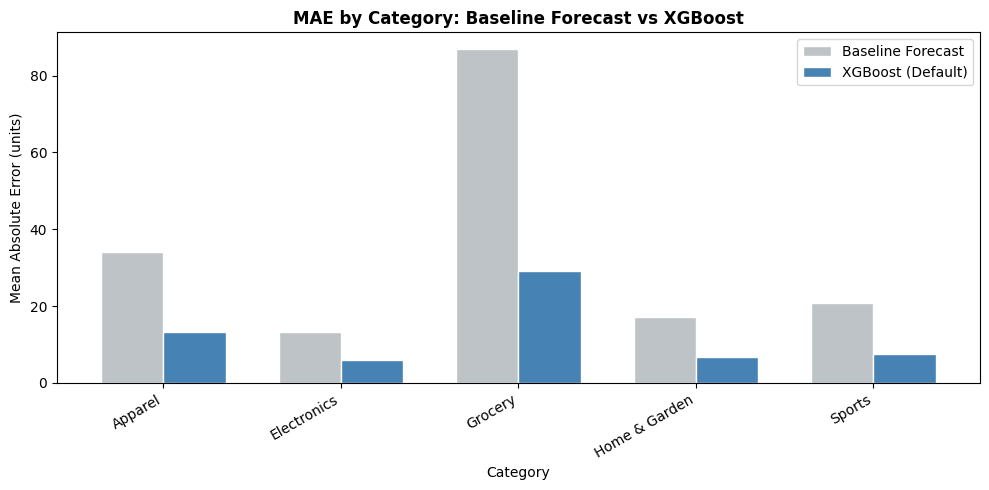


=== Performance by Promotion Status ===
              Actual_Mean  Predicted_Mean  XGBoost_MAE  Baseline_MAE  Count
No Promotion        79.82       76.519997        11.04         31.05   1910
Promotion          101.71       98.239998        20.94         53.61    340


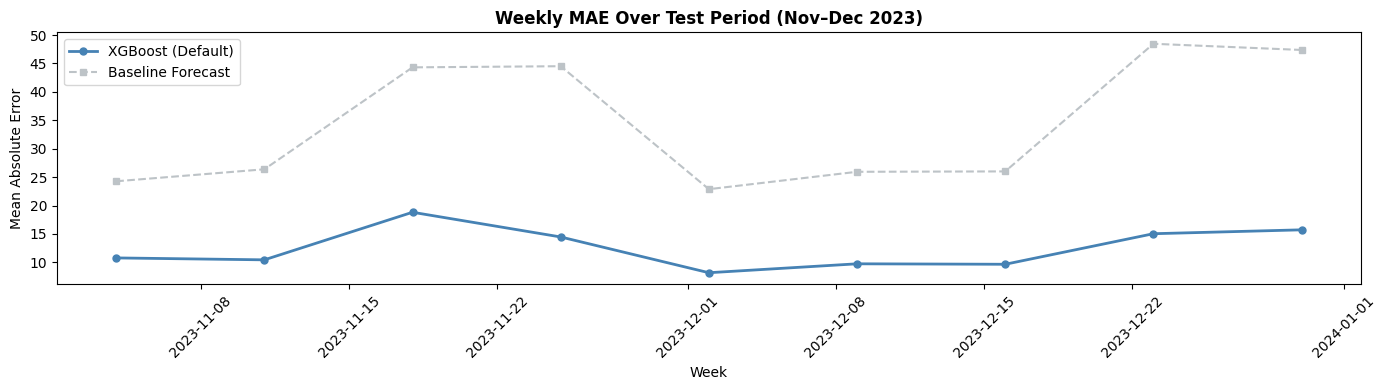

In [ ]:
# Rebuild test_analysis for segmented evaluation
test_analysis = test[['Date', 'Category', 'Region', 'Store Id', 'Product Id',
                        'Promotion Flag', 'Holiday Flag', 'Baseline Forecast']].copy()
test_analysis['actual']           = y_test.values
test_analysis['predicted']         = y_pred_test
test_analysis['baseline_pred']     = baseline_test.values
test_analysis['abs_error']         = np.abs(test_analysis['actual'] - test_analysis['predicted'])
test_analysis['baseline_abs_error']= np.abs(test_analysis['actual'] - test_analysis['baseline_pred'])

# ── MAE by Category ────────────────────────────────────────────────────
cat_metrics = test_analysis.groupby('Category').agg(
    XGBoost_MAE  =('abs_error',         'mean'),
    Baseline_MAE =('baseline_abs_error', 'mean'),
    Mean_Sales   =('actual',             'mean'),
    Count        =('actual',             'count')
).round(2)
cat_metrics['Improvement_%'] = ((cat_metrics['Baseline_MAE'] - cat_metrics['XGBoost_MAE']) /
                                  cat_metrics['Baseline_MAE'] * 100).round(1)
print('=== MAE by Product Category (Test Set) ===')
print(cat_metrics.to_string())

fig, ax = plt.subplots(figsize=(10, 5))
cat_metrics[['Baseline_MAE', 'XGBoost_MAE']].plot(kind='bar', ax=ax,
    color=['#bdc3c7', 'steelblue'], edgecolor='white', width=0.7)
ax.set_title('MAE by Category: Baseline Forecast vs XGBoost', fontweight='bold')
ax.set_ylabel('Mean Absolute Error (units)')
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='right')
ax.legend(['Baseline Forecast', 'XGBoost (Default)'])
plt.tight_layout()
plt.show()

# ── MAE by Promotion Status ────────────────────────────────────────────
promo_analysis = test_analysis.groupby('Promotion Flag').agg(
    Actual_Mean  =('actual',             'mean'),
    Predicted_Mean=('predicted',         'mean'),
    XGBoost_MAE  =('abs_error',         'mean'),
    Baseline_MAE =('baseline_abs_error', 'mean'),
    Count        =('actual',             'count')
).round(2)
promo_analysis.index = ['No Promotion', 'Promotion']
print('\n=== Performance by Promotion Status ===')
print(promo_analysis.to_string())

# ── Weekly MAE over test period ────────────────────────────────────────
weekly_errors = test_analysis.groupby('Date').agg(
    XGBoost_MAE  =('abs_error',          'mean'),
    Baseline_MAE =('baseline_abs_error',  'mean')
).reset_index()

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(weekly_errors['Date'], weekly_errors['XGBoost_MAE'],  'o-',
        color='steelblue', label='XGBoost (Default)', linewidth=2, markersize=5)
ax.plot(weekly_errors['Date'], weekly_errors['Baseline_MAE'], 's--',
        color='#bdc3c7', label='Baseline Forecast', linewidth=1.5, markersize=4)
ax.set_title('Weekly MAE Over Test Period (Nov–Dec 2023)', fontweight='bold')
ax.set_xlabel('Week')
ax.set_ylabel('Mean Absolute Error')
ax.legend()
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

=== Top 10 HARDEST to Predict (highest MAE) ===
                       MAE  Mean_Sales  Std_Sales     CV  MAPE
Store Id Product Id                                           
Store_8  P013        67.49      358.33     101.14  0.282  18.8
         P015        58.39      356.89      65.56  0.184  16.4
Store_7  P015        50.70      271.89      63.36  0.233  18.6
Store_6  P015        49.46      288.11      63.91  0.222  17.2
Store_5  P013        45.09      201.44      52.95  0.263  22.4
         P012        44.81      284.22     120.91  0.425  15.8
Store_8  P011        43.73      247.89      58.85  0.237  17.6
Store_6  P012        43.32      293.11     103.56  0.353  14.8
Store_3  P015        43.23      250.22      33.57  0.134  17.3
Store_8  P014        42.90      314.89      75.91  0.241  13.6

=== Top 10 EASIEST to Predict (lowest MAE) ===
                      MAE  Mean_Sales  Std_Sales     CV  MAPE
Store Id Product Id                                          
Store_9  P003        2.5

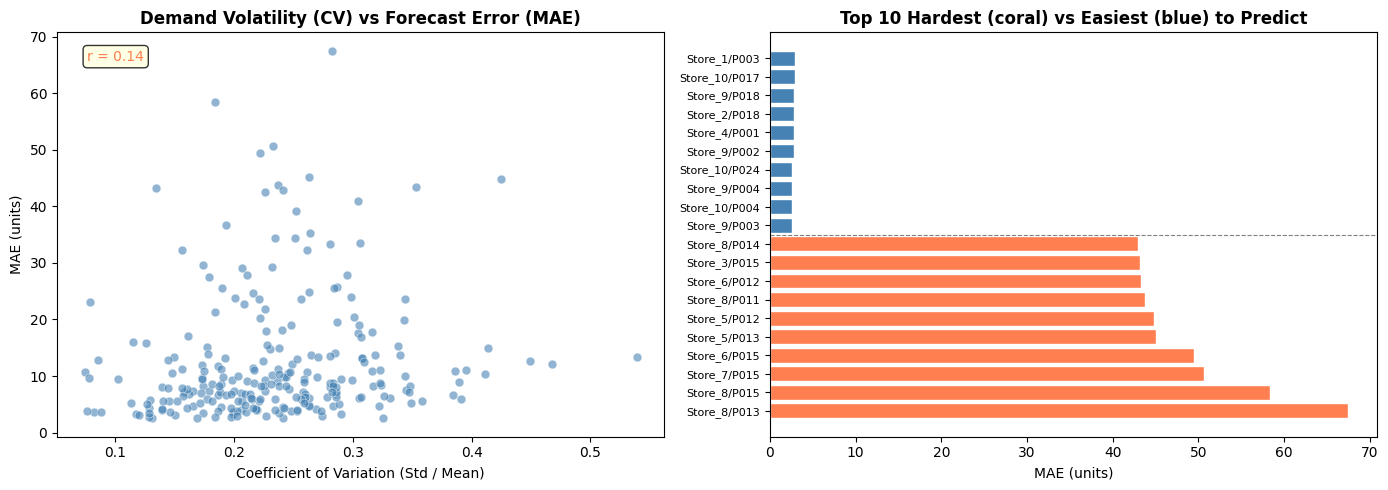


Correlation between CV and MAE: 0.14
Interpretation: If r > 0.5, high-CV products drive most forecast error.
These products may need separate models, safety-stock buffers, or manual override.


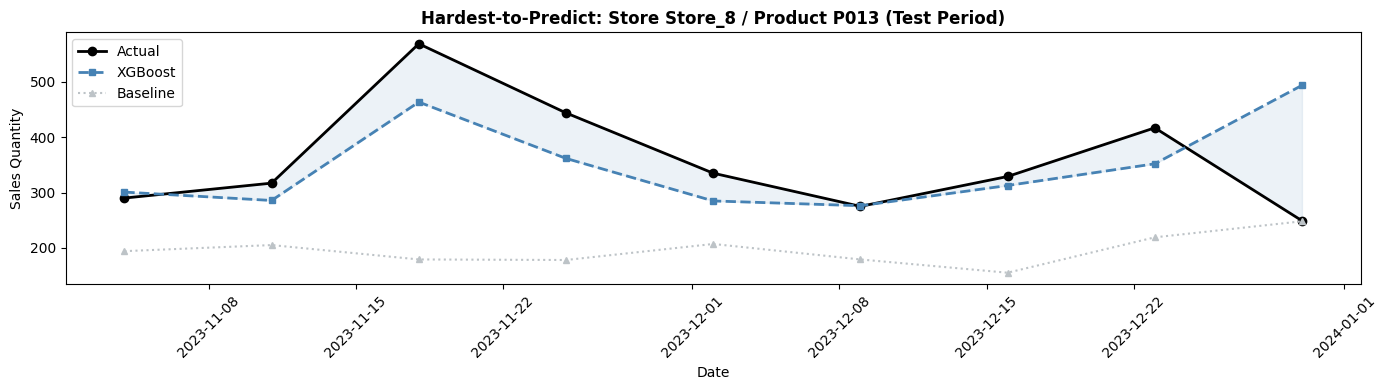

In [ ]:
# ── Hardest-to-Predict Store-Product Combinations ───────────────────────
# Mirrors LightGBM Section 12.4
# High MAE here = demand patterns the model can't capture
# These products may need manual review or separate models

product_errors = test_analysis.groupby(['Store Id', 'Product Id']).agg(
    MAE        = ('abs_error',   'mean'),
    Mean_Sales = ('actual',      'mean'),
    Std_Sales  = ('actual',      'std'),
    Count      = ('actual',      'count')
).round(2)

# CV = coefficient of variation — demand volatility signal
product_errors['CV']   = (product_errors['Std_Sales'] /
                           product_errors['Mean_Sales'].replace(0, np.nan)).round(3)
product_errors['MAPE'] = (product_errors['MAE'] /
                           product_errors['Mean_Sales'].replace(0, np.nan) * 100).round(1)

print('=== Top 10 HARDEST to Predict (highest MAE) ===')
hard = product_errors.nlargest(10, 'MAE')[['MAE', 'Mean_Sales', 'Std_Sales', 'CV', 'MAPE']]
print(hard.to_string())
print()
print('=== Top 10 EASIEST to Predict (lowest MAE) ===')
easy = product_errors.nsmallest(10, 'MAE')[['MAE', 'Mean_Sales', 'Std_Sales', 'CV', 'MAPE']]
print(easy.to_string())

# Scatter: CV vs MAE — do volatile products have higher error?
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(product_errors['CV'], product_errors['MAE'],
                alpha=0.6, s=40, color='steelblue', edgecolors='white', linewidth=0.5)
axes[0].set_title('Demand Volatility (CV) vs Forecast Error (MAE)', fontweight='bold')
axes[0].set_xlabel('Coefficient of Variation (Std / Mean)')
axes[0].set_ylabel('MAE (units)')
cv_corr = product_errors['CV'].corr(product_errors['MAE'])
axes[0].text(0.05, 0.93, f'r = {cv_corr:.2f}', transform=axes[0].transAxes,
             fontsize=10, color='coral',
             bbox=dict(boxstyle='round,pad=0.3', facecolor='lightyellow', alpha=0.8))

# Top 10 hard vs easy — MAE bar chart
top10_hard = product_errors.nlargest(10, 'MAE')['MAE']
top10_easy = product_errors.nsmallest(10, 'MAE')['MAE']
combined   = pd.concat([top10_hard, top10_easy])
colors_bar = ['coral'] * 10 + ['steelblue'] * 10
axes[1].barh(range(len(combined)), combined.values, color=colors_bar, edgecolor='white')
axes[1].set_yticks(range(len(combined)))
axes[1].set_yticklabels(
    [f'{s}/{p}' for s, p in top10_hard.index] +
    [f'{s}/{p}' for s, p in top10_easy.index],
    fontsize=8
)
axes[1].axhline(9.5, color='black', linestyle='--', linewidth=0.8, alpha=0.5)
axes[1].set_title('Top 10 Hardest (coral) vs Easiest (blue) to Predict', fontweight='bold')
axes[1].set_xlabel('MAE (units)')

plt.tight_layout()
plt.show()

print(f'\nCorrelation between CV and MAE: {cv_corr:.2f}')
print('Interpretation: If r > 0.5, high-CV products drive most forecast error.')
print('These products may need separate models, safety-stock buffers, or manual override.')

# Sample product visualisation — hardest product, actual vs predicted vs baseline
hard_store, hard_product = product_errors.nlargest(1, 'MAE').index[0]
sample = test_analysis[
    (test_analysis['Store Id'] == hard_store) &
    (test_analysis['Product Id'] == hard_product)
].sort_values('Date')

if len(sample) > 0:
    fig, ax = plt.subplots(figsize=(14, 4))
    ax.plot(sample['Date'], sample['actual'],       'o-', color='black',
            label='Actual',       linewidth=2, markersize=6)
    ax.plot(sample['Date'], sample['predicted'],    's--', color='steelblue',
            label='XGBoost',      linewidth=2, markersize=5)
    ax.plot(sample['Date'], sample['baseline_pred'], '^:', color='#bdc3c7',
            label='Baseline',     linewidth=1.5, markersize=4)
    ax.fill_between(sample['Date'], sample['actual'], sample['predicted'],
                    alpha=0.1, color='steelblue')
    ax.set_title(f'Hardest-to-Predict: Store {hard_store} / Product {hard_product} (Test Period)',
                 fontweight='bold')
    ax.set_xlabel('Date'); ax.set_ylabel('Sales Quantity')
    ax.legend(); ax.tick_params(axis='x', rotation=45)
    plt.tight_layout()
    plt.show()

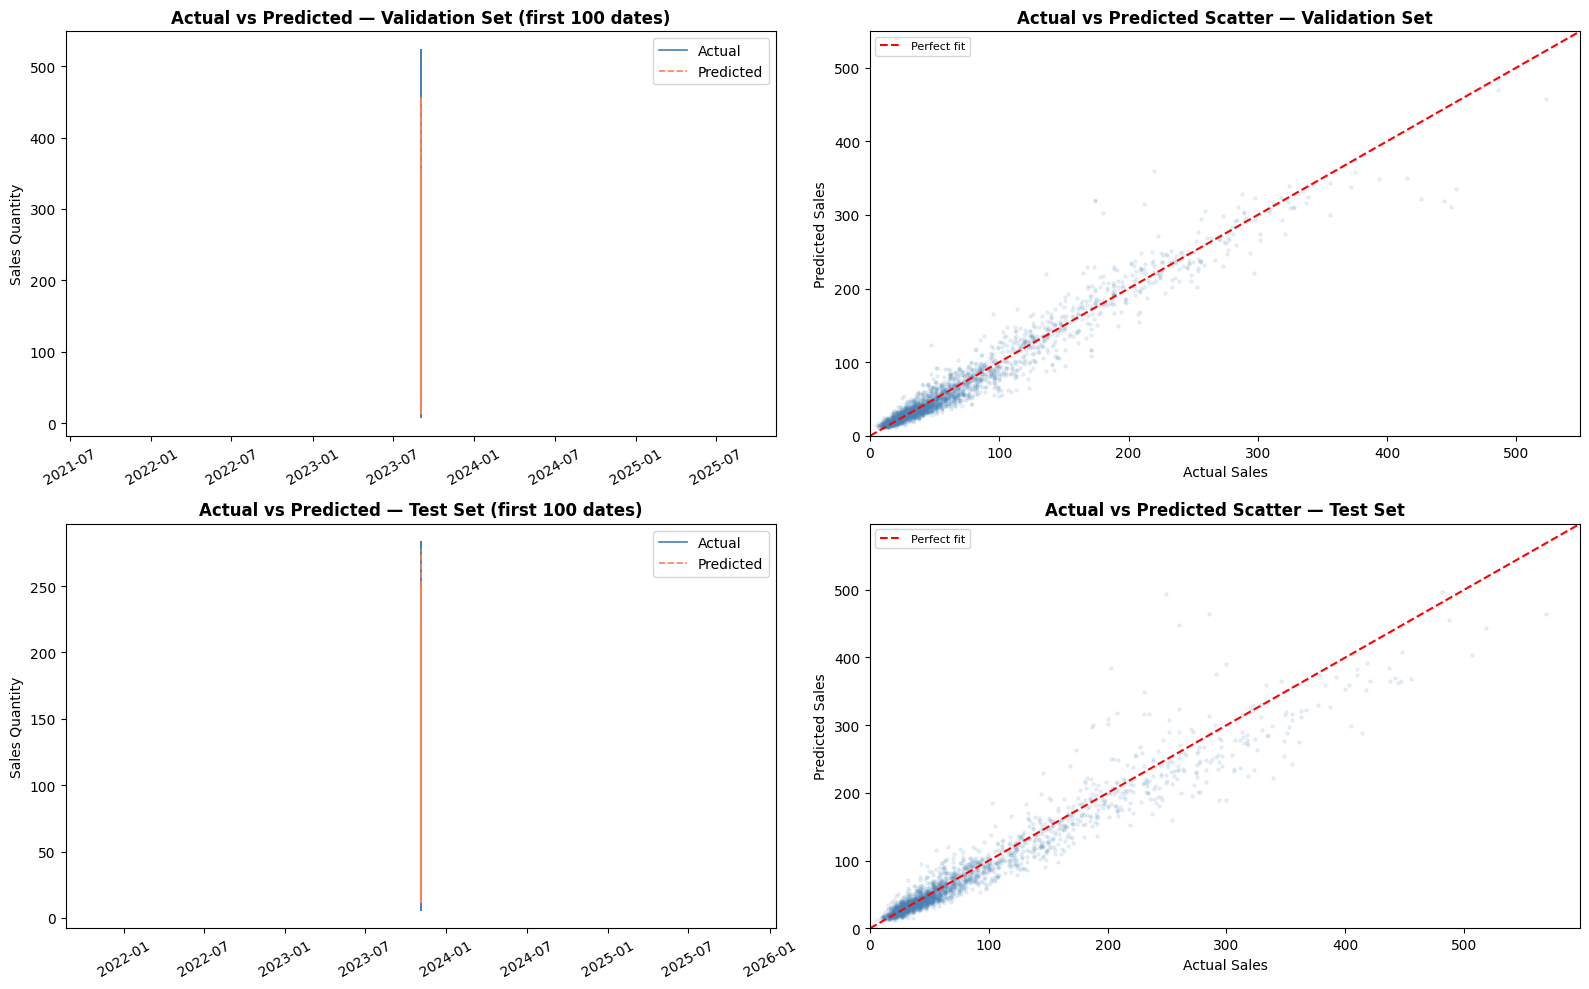

Scatter interpretation: points on the 45° line = perfect prediction.
  Fan above the line → underprediction at high volumes.
  Fan below the line → overprediction at high volumes (heteroscedasticity).


In [ ]:
# ── Actual vs Predicted Plot ─────────────────────────────────────────────
# Use date-sorted first 100 rows so the x-axis is chronologically meaningful.
val_sorted  = val.sort_values('Date').head(100)
test_sorted = test.sort_values('Date').head(100)

val_idx  = val_sorted.index
test_idx = test_sorted.index

# Align predictions to the sorted indices
val_df = val.copy()
val_df['pred'] = y_pred_val
test_df = test.copy()
test_df['pred'] = y_pred_test

val_plot  = val_df.sort_values('Date').head(100)
test_plot = test_df.sort_values('Date').head(100)

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Time-series plots (date-sorted)
axes[0,0].plot(val_plot['Date'], val_plot['Sales Quantity'],  label='Actual',    color='steelblue', linewidth=1.2)
axes[0,0].plot(val_plot['Date'], val_plot['pred'],            label='Predicted', color='coral', linewidth=1.2, linestyle='--')
axes[0,0].set_title('Actual vs Predicted — Validation Set (first 100 dates)', fontweight='bold')
axes[0,0].set_ylabel('Sales Quantity')
axes[0,0].tick_params(axis='x', rotation=30)
axes[0,0].legend()

axes[1,0].plot(test_plot['Date'], test_plot['Sales Quantity'], label='Actual',    color='steelblue', linewidth=1.2)
axes[1,0].plot(test_plot['Date'], test_plot['pred'],           label='Predicted', color='coral', linewidth=1.2, linestyle='--')
axes[1,0].set_title('Actual vs Predicted — Test Set (first 100 dates)', fontweight='bold')
axes[1,0].set_ylabel('Sales Quantity')
axes[1,0].tick_params(axis='x', rotation=30)
axes[1,0].legend()

# Scatter plots: actual vs predicted with 45° reference line
for ax, y_true, y_pred, label in [
    (axes[0,1], y_val.values,  y_pred_val,  'Validation'),
    (axes[1,1], y_test.values, y_pred_test, 'Test')
]:
    ax.scatter(y_true, y_pred, alpha=0.1, s=5, color='steelblue')
    lim = max(y_true.max(), y_pred.max()) * 1.05
    ax.plot([0, lim], [0, lim], color='red', linestyle='--', linewidth=1.5, label='Perfect fit')
    ax.set_title(f'Actual vs Predicted Scatter — {label} Set', fontweight='bold')
    ax.set_xlabel('Actual Sales')
    ax.set_ylabel('Predicted Sales')
    ax.legend(fontsize=8)
    ax.set_xlim(0, lim)
    ax.set_ylim(0, lim)

plt.tight_layout()
plt.show()

print('Scatter interpretation: points on the 45° line = perfect prediction.')
print('  Fan above the line → underprediction at high volumes.')
print('  Fan below the line → overprediction at high volumes (heteroscedasticity).')

In [ ]:
# ── Stockout Risk Detection ──────────────────────────────────────────────
# Assumption: Inventory Start is observed before the week ends (no leakage).
# Assumption: No mid-week replenishment — inventory at start is all that's available.
context_cols = ['Date', 'Store Id', 'Product Id', 'Product Name',
                'Category', 'Region', 'Inventory Start', 'Stockout Flag']

context = df_fe[df_fe['Date'].isin(test['Date'])][context_cols].copy()
context = context.reset_index(drop=True)

test_results = context.copy()
test_results['actual_sales']    = y_test.values
test_results['predicted_sales'] = np.clip(y_pred_test, 0, None).astype(int)
test_results['stockout_risk']   = (test_results['predicted_sales'] >
                                   test_results['Inventory Start']).astype(int)
test_results['actual_stockout'] = test_results['Stockout Flag'].astype(int)
test_results['inventory_gap']   = (test_results['predicted_sales'] -
                                   test_results['Inventory Start'])
test_results['weeks_of_supply'] = (test_results['Inventory Start'] /
                                   test_results['predicted_sales'].replace(0, 1)).round(1)

at_risk = test_results[test_results['stockout_risk'] == 1].sort_values(
    'inventory_gap', ascending=False
)

# Alert quality metrics
true_pos  = ((test_results['stockout_risk'] == 1) & (test_results['actual_stockout'] == 1)).sum()
false_pos = ((test_results['stockout_risk'] == 1) & (test_results['actual_stockout'] == 0)).sum()
false_neg = ((test_results['stockout_risk'] == 0) & (test_results['actual_stockout'] == 1)).sum()
precision = true_pos / (true_pos + false_pos) if (true_pos + false_pos) > 0 else 0
recall    = true_pos / (true_pos + false_neg) if (true_pos + false_neg) > 0 else 0

print(f'Total test rows:         {len(test_results)}')
print(f'Predicted stockout risk: {len(at_risk)} ({len(at_risk)/len(test_results)*100:.1f}%)')
print(f'Alert precision:         {precision:.2f}  ← of alerts fired, % were real stockouts')
print(f'Alert recall:            {recall:.2f}  ← of real stockouts, % were caught')
print(f'False positive rate:     {false_pos}/{len(at_risk)} alerts were not actual stockouts')
print(f'\nTop 10 products at highest stockout risk:')
print(at_risk[['Date','Store Id','Product Name','Category',
               'Region','Inventory Start','predicted_sales',
               'inventory_gap']].head(10).to_string(index=False))

Total test rows:         2250
Predicted stockout risk: 289 (12.8%)
Alert precision:         0.92  ← of alerts fired, % were real stockouts
Alert recall:            0.52  ← of real stockouts, % were caught
False positive rate:     24/289 alerts were not actual stockouts

Top 10 products at highest stockout risk:
      Date Store Id Product Name Category Region  Inventory Start  predicted_sales  inventory_gap
2023-12-30  Store_8         Eggs  Grocery   West              249              493            244
2023-12-23  Store_6        Pasta  Grocery   East              260              448            188
2023-12-30  Store_5         Eggs  Grocery   East              203              384            181
2023-11-18  Store_6         Milk  Grocery   East              285              464            179
2023-11-18  Store_3        Pasta  Grocery  South              231              348            117
2023-12-30  Store_7        Pasta  Grocery   West              188              299            111
2

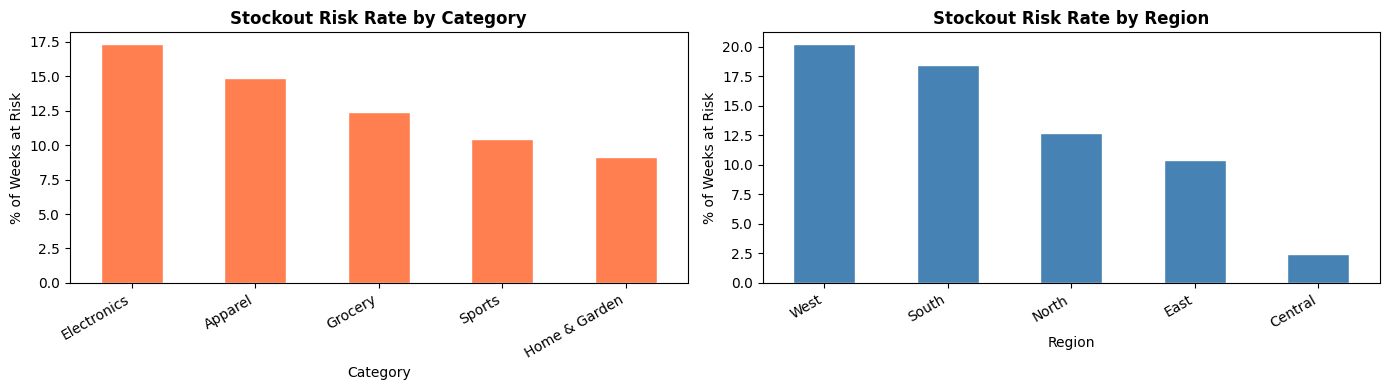

In [ ]:
# ── Stockout Risk by Category & Region ────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# By category
cat_risk = test_results.groupby('Category')['stockout_risk'].mean() * 100
cat_risk.sort_values(ascending=False).plot(kind='bar', ax=axes[0],
    color='coral', edgecolor='white')
axes[0].set_title('Stockout Risk Rate by Category', fontweight='bold')
axes[0].set_ylabel('% of Weeks at Risk')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=30, ha='right')

# By region
reg_risk = test_results.groupby('Region')['stockout_risk'].mean() * 100
reg_risk.sort_values(ascending=False).plot(kind='bar', ax=axes[1],
    color='steelblue', edgecolor='white')
axes[1].set_title('Stockout Risk Rate by Region', fontweight='bold')
axes[1].set_ylabel('% of Weeks at Risk')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=30, ha='right')

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from xgboost import XGBRegressor
import joblib

param_grid = {
    'n_estimators':      [300, 500, 700],
    'learning_rate':     [0.01, 0.05, 0.1],
    'max_depth':         [4, 6, 8],
    'subsample':         [0.7, 0.8, 0.9],
    'colsample_bytree':  [0.7, 0.8, 0.9],
    'min_child_weight':  [1, 3, 5],
    'gamma':             [0, 0.1, 0.3],
    'reg_alpha':         [0, 0.1, 0.5],
    'reg_lambda':        [1, 1.5, 2],
}

# n_iter=50 over 3^9 = 19,683 combinations covers ~0.25% of space
# Chosen to balance search quality with Colab compute budget (~20 min).
# For production, increase to n_iter=200 or use Optuna for smarter search.
tscv     = TimeSeriesSplit(n_splits=5)
xgb_base = XGBRegressor(random_state=42, eval_metric='rmse', verbosity=0)

random_search = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=param_grid,
    n_iter=50,
    scoring='neg_mean_absolute_error',
    cv=tscv,
    verbose=2,
    random_state=42,
    n_jobs=-1
)

print('Starting RandomizedSearchCV (TimeSeriesSplit — no future data leakage)...')
random_search.fit(X_train, y_train)

best_model = random_search.best_estimator_
joblib.dump(best_model, '/content/drive/My Drive/Colab Notebooks/DSCapstone/xgb_best_model.pkl')

# Save full CV results for reproducibility and analysis
cv_results = pd.DataFrame(random_search.cv_results_)
cv_results.to_csv('/content/drive/My Drive/Colab Notebooks/DSCapstone/xgb_cv_results.csv', index=False)

print(f'\nBest parameters: {random_search.best_params_}')
print(f'Best CV MAE:     {-random_search.best_score_:.2f}')
print('Model saved to Drive.')
print('CV results saved for reproducibility (xgb_cv_results.csv).')

Starting RandomizedSearchCV (TimeSeriesSplit — no future data leakage)...
Fitting 5 folds for each of 50 candidates, totalling 250 fits

Best parameters: {'subsample': 0.8, 'reg_lambda': 1, 'reg_alpha': 0.5, 'n_estimators': 500, 'min_child_weight': 5, 'max_depth': 4, 'learning_rate': 0.05, 'gamma': 0.3, 'colsample_bytree': 0.7}
Best CV MAE:     10.42
Model saved to Drive.
CV results saved for reproducibility (xgb_cv_results.csv).


In [ ]:
y_pred_val_tuned  = best_model.predict(X_val)
y_pred_test_tuned = best_model.predict(X_test)

# Clip negative predictions
y_pred_val_tuned  = np.clip(y_pred_val_tuned,  0, None)
y_pred_test_tuned = np.clip(y_pred_test_tuned, 0, None)

print('=== Tuned XGBoost ===')
evaluate_model(y_val,  y_pred_val_tuned,  'Tuned XGBoost (Val) ')
evaluate_model(y_test, y_pred_test_tuned, 'Tuned XGBoost (Test)')

print('\n=== Original XGBoost ===')
evaluate_model(y_val,  y_pred_val,  'Original (Val)  ')
evaluate_model(y_test, y_pred_test, 'Original (Test) ')

print('\n=== Baseline ===')
evaluate_model(y_val,  baseline_val.values,  'Baseline (Val)  ')
evaluate_model(y_test, baseline_test.values, 'Baseline (Test) ')

# Summary: which metric improved most, and where does the model still struggle?
print('\n=== Summary ===')
print('Review the table above and fill in:')
print('  1. Which metric improved most vs baseline (MAE / RMSE / MAPE)?')
print('  2. Did tuning improve over the original XGBoost, and by how much?')
print('  3. Where does the model still underperform (e.g., high-variance products,')
print('     sparse holiday weeks, specific regions)?')
print('  4. Recommended next steps (SHAP analysis, log-target transform, ensemble).')

=== Tuned XGBoost ===
Tuned XGBoost (Val) :
  MAE  = 9.71 units
  RMSE = 15.60 units
  MAPE = 16.81%
  R²   = 0.9473
Tuned XGBoost (Test):
  MAE  = 12.13 units
  RMSE = 20.93 units
  MAPE = 16.61%
  R²   = 0.9335

=== Original XGBoost ===
Original (Val)  :
  MAE  = 9.80 units
  RMSE = 15.85 units
  MAPE = 17.18%
  R²   = 0.9456
Original (Test) :
  MAE  = 12.54 units
  RMSE = 21.64 units
  MAPE = 16.86%
  R²   = 0.9289

=== Baseline ===
Baseline (Val)  :
  MAE  = 28.65 units
  RMSE = 46.51 units
  MAPE = 36.65%
  R²   = 0.5319
Baseline (Test) :
  MAE  = 34.46 units
  RMSE = 56.42 units
  MAPE = 38.33%
  R²   = 0.5167

=== Summary ===
Review the table above and fill in:
  1. Which metric improved most vs baseline (MAE / RMSE / MAPE)?
  2. Did tuning improve over the original XGBoost, and by how much?
  3. Where does the model still underperform (e.g., high-variance products,
     sparse holiday weeks, specific regions)?
  4. Recommended next steps (SHAP analysis, log-target transform, en

In [ ]:
# ── Final three-way comparison table ─────────────────────────────────────
y_pred_val_tuned  = np.clip(best_model.predict(X_val),  0, None)
y_pred_test_tuned = np.clip(best_model.predict(X_test), 0, None)

r_test_tuned = evaluate_model(y_test, y_pred_test_tuned, 'XGBoost (Tuned) — Test')
results.append({**r_test_tuned, 'model': 'XGBoost (Tuned)'})

print('\n' + '='*70)
print('FINAL RESULTS: MODEL COMPARISON ON TEST SET (Nov–Dec 2023)')
print('='*70)
final_df = pd.DataFrame(results)
final_df = final_df.drop(columns=['label'], errors='ignore')
print(final_df.set_index('model')[['MAE','RMSE','MAPE','R2']].round(2).to_string())

# ── Business impact calculation ────────────────────────────────────────
n_combos = test_analysis[['Store Id','Product Id']].drop_duplicates().shape[0]
n_weeks  = test_analysis['Date'].nunique()

baseline_total = test_analysis['baseline_abs_error'].sum()
xgb_total      = test_analysis['abs_error'].sum()
reduction      = baseline_total - xgb_total

print('\n' + '='*70)
print('BUSINESS IMPACT ANALYSIS')
print('='*70)
print(f'Store-product combinations in test: {n_combos}')
print(f'Test period weeks:                  {n_weeks}')
print(f'\nTotal absolute forecast error (test period):')
print(f'  Baseline Forecast: {baseline_total:,.0f} units')
print(f'  XGBoost (Default): {xgb_total:,.0f} units')
print(f'  Error reduction:   {reduction:,.0f} units ({reduction/baseline_total*100:.1f}%)')
print(f'\nPer store-product per week:')
print(f'  Baseline avg error: {baseline_total/(n_combos*n_weeks):.1f} units')
print(f'  XGBoost avg error:  {xgb_total/(n_combos*n_weeks):.1f} units')
print(f'\nImplication: Each unit of error reduction = one less unit of excess inventory')
print(f'or one fewer lost sale. XGBoost reduces forecast error by {reduction:,.0f} unit-weeks')
print(f'across the test period.')

XGBoost (Tuned) — Test:
  MAE  = 12.13 units
  RMSE = 20.93 units
  MAPE = 16.61%
  R²   = 0.9335

FINAL RESULTS: MODEL COMPARISON ON TEST SET (Nov–Dec 2023)
                        MAE   RMSE   MAPE    R2
model                                          
XGBoost (Default)     12.54  21.64  16.86  0.93
Baseline Forecast     34.46  56.42  38.33  0.52
XGBoost (Log-Target)  12.55  21.34  16.69  0.93
XGBoost (Tuned)       12.13  20.93  16.61  0.93

BUSINESS IMPACT ANALYSIS
Store-product combinations in test: 250
Test period weeks:                  9

Total absolute forecast error (test period):
  Baseline Forecast: 77,533 units
  XGBoost (Default): 28,210 units
  Error reduction:   49,323 units (63.6%)

Per store-product per week:
  Baseline avg error: 34.5 units
  XGBoost avg error:  12.5 units

Implication: Each unit of error reduction = one less unit of excess inventory
or one fewer lost sale. XGBoost reduces forecast error by 49,323 unit-weeks
across the test period.
